# EDA - BIODIVERSITY-GUARD-Predict
## Hito 3: Data Understanding y Análisis Exploratorio de Datos

**Entrada única:** `datos/datasets_eda/dataset_panel_semanal_COMPLETO.csv`, el panel semanal que sale del preprocesamiento (543 municipios x 251 semanas, de lunes 2022-01-03 a lunes 2026-10-19). La clave es `(municipio_norm, uf, semana)`.

### Definición del problema (contexto)
- **Frente 1 (regresión):** `focos_t1` es el número de focos de calor (`num_incendios`) de la semana siguiente. `focos_4s` es la suma de las 4 semanas siguientes. El panel es completo, con ceros.
- **Frente 2 (clasificación):** clase de riesgo de fuego de la semana siguiente (solo `t+1`), a partir de `riesgo_fuego_promedio`: Bajo (hasta 0.40), Moderado (0.40 a 0.70], Alto (0.70 a 0.95] y Crítico (más de 0.95). Solo existe en semanas-municipio con focos.
- **Partición:** entrenamiento 2022 a 2024 (con validación cruzada temporal), margen de 4 semanas, prueba final con 2025 completo. 2026 es un flujo simulado para la base común y no entrena.

Los targets se calculan aquí **solo para explorarlos** (función `agregar_targets_exploratorios`). Su definición formal y su uso en el modelado corresponden a Data Preparation. En este notebook no se entrena ningún modelo.

### Regla metodológica anti fuga
Toda cifra que sirva para **decidir** algo (valores atípicos, normalidad, correlaciones, umbrales, selección de variables) se calcula **solo con 2022 a 2024**. Los años 2025 y 2026 se usan únicamente para describir y para la sección de desplazamiento (drift). Para las cifras que usan los targets se aplica además el margen de 4 semanas: se excluyen las semanas de diciembre de 2024 cuyo futuro cae en 2025. Cada sección indica qué subconjunto usa.


## Índice de figuras

| Figura | Título | Sección |
|---|---|---|
| 1 | Semanas con focos y sin `RiscoFogo`, por año (2022 a 2026) | 2. Valores faltantes |
| 2 | Distribución de los targets, entrenamiento 2022 a 2024 | 3. Variables objetivo |
| 3 | Clase de riesgo de fuego por año (2022 a 2026) | 3. Variables objetivo |
| 4 | Persistencia de la clase de riesgo (semana t a t+1), 2022 a 2024 | 3. Variables objetivo |
| 5 | Clase de riesgo de fuego por mes del año, 2022 a 2024 | 3. Variables objetivo |
| 6 | Autocorrelación del total semanal de focos, 2022 a 2024 | 4. Persistencia y baseline |
| 7 | Boxplots de focos, clima y calidad del aire, 2022 a 2024 (focos en escala symlog) | 5. Valores atípicos |
| 8 | Porcentaje de valores fuera de rango, IQR frente a 3 desviaciones estándar (2022 a 2024) | 5. Valores atípicos |
| 9 | Gráficos Q-Q contra la normal (muestra de 5,000 filas, 2022 a 2024) | 6. Prueba de normalidad (D'Agostino-Pearson) |
| 10 | Total semanal de focos de calor, años superpuestos (2022 a 2026) | 7. Evolución temporal |
| 11 | Perfil mensual de focos, promedio 2022 a 2024 | 7. Evolución temporal |
| 12 | Variación interanual de focos por estado y mes (2025 frente a 2024 y 2026 frente a 2025) | 7. Evolución temporal |
| 13 | Focos de calor por estado, 2022 a 2024 | 8. Distribución espacial |
| 14 | Focos de calor por municipio, 2022 a 2024 (tamaño y color según el total) | 8. Distribución espacial |
| 15 | Focos y error de la persistencia por estado, 2022 a 2024 | 8. Distribución espacial |
| 16 | Pearson y Spearman de las predictoras con los targets (2022 a 2024) | 9. Correlaciones con los targets |
| 17 | Spearman con focos_t1 por temporada (2022 a 2024) | 9. Correlaciones con los targets |
| 18 | Spearman con focos_t1, simple y parcial (2022 a 2024) | 9. Correlaciones con los targets |
| 19 | Correlación cruzada de NASA POWER con los focos (2022 a 2024) | 9. Correlaciones con los targets |
| 20 | Correlación entre predictoras, 2022 a 2024 | 10. Colinealidad entre predictoras |
| 21 | Matriz de covarianza en escala original (2022 a 2024) | 11. Covarianza y dispersión |
| 22 | Matriz de covarianza de variables estandarizadas, igual a la correlación (2022 a 2024) | 11. Covarianza y dispersión |
| 23 | Dispersión contra focos_t1, grupo 1 de 2 (muestra de 5,000 filas, 2022 a 2024) | 11. Covarianza y dispersión |
| 24 | Dispersión contra focos_t1, grupo 2 de 2 (muestra de 5,000 filas, 2022 a 2024) | 11. Covarianza y dispersión |
| 25 | Dispersión contra focos_4s, grupo 1 de 2 (muestra de 5,000 filas, 2022 a 2024) | 11. Covarianza y dispersión |
| 26 | Dispersión contra focos_4s, grupo 2 de 2 (muestra de 5,000 filas, 2022 a 2024) | 11. Covarianza y dispersión |
| 27 | Predictoras principales por clase de riesgo de la semana siguiente (2022 a 2024) | 11. Covarianza y dispersión |
| 28 | Pairplot (muestra de 3,000 filas, 2022 a 2024) | 11. Covarianza y dispersión |
| 29 | Hectáreas de alertas DETER frente a focos, por semana (2022 a 2024) | 12. Contexto DETER y SISAM |
| 30 | Pronóstico 2026 frente a reanálisis 2025, misma época del año (semanas 1 a 42) | 12. Contexto DETER y SISAM |
| 31 | Las 15 variables con mayor desplazamiento frente a 2022 a 2024 (estadístico KS, semanas 1 a 42) | 13. Desplazamiento entre periodos (drift) |
| 32 | Municipios en alerta por semana, 2022 a 2024 | 14. Evidencia para umbrales de KPI |


## Configuración del entorno


In [1]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd

# ---------------------------------------------------------------------------
# 1. Entorno: Google Colab (Drive) o ejecucion local
# ---------------------------------------------------------------------------
USAR_DRIVE = True   # True en Colab; False para trabajar con la carpeta local del repositorio
BASE_DRIVE = Path("/content/drive/MyDrive/BIODIVERSITY_GUARD")

if USAR_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = BASE_DRIVE
    except ImportError:
        print("No se detecto Google Colab: se usa la raiz local del repositorio.")
        USAR_DRIVE = False

if not USAR_DRIVE:
    # la raiz es la primera carpeta (hacia arriba desde la actual) que contiene "datos"
    _aqui = Path.cwd().resolve()
    BASE = next((p for p in [_aqui, *_aqui.parents] if (p / "datos").is_dir()), None)
    if BASE is None:
        raise FileNotFoundError("No se encontro la carpeta 'datos' subiendo desde " + str(_aqui))

if not BASE.exists():
    raise FileNotFoundError(f"No existe BASE = {BASE}. Verifica la carpeta BIODIVERSITY_GUARD en Drive.")

# ---------------------------------------------------------------------------
# 2. Rutas (todas salen de BASE)
# ---------------------------------------------------------------------------
DIR_PREP = BASE / "datos" / "datasets_preprocesamiento"
DIR_BDQ = DIR_PREP / "BDQueimadas"
DIR_DETER = DIR_PREP / "DETER"
DIR_NASA = DIR_PREP / "NasaPower"
DIR_SISAM = DIR_PREP / "SISAM"
DIR_EDA = BASE / "datos" / "datasets_eda"

# ---------------------------------------------------------------------------
# 3. Constantes comunes (identicas en los 7 notebooks)
# ---------------------------------------------------------------------------
FECHA_INICIO_DATOS = "2022-01-01"
FECHA_FIN_EXTRACCION = "2026-11-01"      # DETER y BDQueimadas
PRIMERA_SEMANA = "2022-01-03"             # primer lunes con semana completa (2022-01-01 es sabado)
ULTIMA_SEMANA = "2026-10-19"              # lunes de la ultima semana completa (termina domingo 2026-10-25)
SATELITE_REFERENCIA = "AQUA_M-T"
ESTADOS_AMAZONIA_LEGAL = ["ACRE", "AMAPÁ", "AMAZONAS", "MARANHÃO", "MATO GROSSO", "PARÁ", "RONDÔNIA", "RORAIMA", "TOCANTINS"]
MAPA_UF = {"ACRE": "AC", "AMAPÁ": "AP", "AMAZONAS": "AM", "MARANHÃO": "MA", "MATO GROSSO": "MT", "PARÁ": "PA", "RONDÔNIA": "RO", "RORAIMA": "RR", "TOCANTINS": "TO"}
CORRECCIONES_MUNICIPIO = {"ELDORADO DOS CARAJAS": "ELDORADO DO CARAJAS", "SANTA ISABEL DO PARA": "SANTA IZABEL DO PARA"}
FECHA_CORTE_CENTROIDES = "2024-12-31"     # los centroides se fijan con focos hasta esta fecha

# ---------------------------------------------------------------------------
# 4. Funciones comunes
# ---------------------------------------------------------------------------
def normalizar_texto(texto):
    # mayusculas, sin tildes ni espacios sobrantes
    if pd.isna(texto):
        return texto
    texto = str(texto).upper().strip()
    return unicodedata.normalize("NFKD", texto).encode("ASCII", "ignore").decode("utf-8")


def semana_lunes(fecha):
    # lunes de la semana (lunes a domingo) de cada fecha; recibe una Serie de fechas
    f = pd.to_datetime(fecha).dt.normalize()
    return f - pd.to_timedelta(f.dt.day_of_week, unit="D")


SEMANAS = pd.date_range(PRIMERA_SEMANA, ULTIMA_SEMANA, freq="W-MON")   # calendario de semanas completas
assert len(SEMANAS) == 251, f"El calendario deberia tener 251 semanas y tiene {len(SEMANAS)}"
assert (SEMANAS.day_of_week == 0).all(), "Todas las semanas deben empezar en lunes"


def verificar_entradas(archivos):
    # imprime los archivos de entrada con su tamano y falla si falta alguno
    faltan = []
    for a in map(Path, archivos):
        if a.exists():
            print(f"  OK  {a.relative_to(BASE)}  ({a.stat().st_size / 1e6:,.1f} MB)")
        else:
            faltan.append(a)
    if faltan:
        lista = "\n".join(f"  - {a}" for a in faltan)
        raise FileNotFoundError("Faltan archivos de entrada (copialos a esas carpetas y vuelve a ejecutar):\n" + lista)


print("BASE:", BASE)
print("Calendario:", SEMANAS[0].date(), "a", SEMANAS[-1].date(), f"({len(SEMANAS)} semanas)")


No se detecto Google Colab: se usa la raiz local del repositorio.
BASE: C:\UPC-DOCS\CICLO7\MACHINE LEARNING\HITO3\BIODIVERSITY_GUARD
Calendario: 2022-01-03 a 2026-10-19 (251 semanas)


In [2]:
import warnings

import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import SymLogNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 70
pd.set_option("display.max_columns", None)

ALEATORIO = 42
CLAVE = ["municipio_norm", "uf"]


def mostrar(tabla, decimales=2):
    # imprime una tabla con miles separados por coma y decimales controlados
    print(tabla.to_string(float_format=lambda v: f"{v:,.{decimales}f}"))


## 1. Carga y visión general

Se carga el panel y se verifica su forma (136,293 filas x 31 columnas). Se agregan tres columnas auxiliares: `anio`, `mes` (ambos según el lunes de la semana) y `temporada` (seca de julio a noviembre, húmeda el resto), además de `sem_anio` (número de semana dentro del año, de 1 a 53). **Subconjunto:** todos los años, solo descriptivo.

Diccionario breve de columnas por grupo:

| Grupo | Columnas |
|---|---|
| Identificación | `semana`, `municipio_norm`, `uf`, `lat`, `lon` |
| Focos de calor (BDQueimadas) | `num_incendios`, `frp_total`, `frp_promedio` |
| `RiscoFogo` | `riesgo_fuego_promedio`, `riesgo_fuego_max` |
| Clima de BDQueimadas (solo si hubo focos) | `precipitacion_promedio`, `dias_sin_lluvia_promedio` |
| Clima NASA POWER | `T2M`, `RH2M`, `WS2M`, `T2M_MAX`, `precip_nasa_sem`, `dias_sin_lluvia_nasa`, `precip_acum_30d`, `precip_acum_120d` |
| Calidad del aire SISAM | `pm10_reanalise`, `pm2_5_reanalise`, `o3_reanalise`, `no2_reanalise`, `co_reanalise`, `so2_reanalise`, `dias_sisam`, `fuente_sisam` |
| Contexto DETER (solo KPI) | `deter_num_alertas`, `deter_area_ha`, `deter_num_alertas_area_protegida` |


In [3]:
RUTA_PANEL = DIR_EDA / "dataset_panel_semanal_COMPLETO.csv"
verificar_entradas([RUTA_PANEL])

df = pd.read_csv(RUTA_PANEL, parse_dates=["semana"])
assert df.shape == (136293, 31), f"Forma inesperada: {df.shape}"
df = df.sort_values(CLAVE + ["semana"]).reset_index(drop=True)

df["anio"] = df["semana"].dt.year
df["mes"] = df["semana"].dt.month
df["temporada"] = np.where(df["mes"].between(7, 11), "seca", "humeda")
df["sem_anio"] = (df["semana"].dt.day_of_year - 1) // 7 + 1

print("Forma:", df.shape)
print("Rango de semanas:", df["semana"].min().date(), "a", df["semana"].max().date())
print("Municipios (municipio_norm, uf):", df[CLAVE].drop_duplicates().shape[0], "| semanas:", df["semana"].nunique())
print("\nFilas por año:")
print(df["anio"].value_counts().sort_index().to_string())
print("\nTipos de dato:")
print(df.dtypes.value_counts().to_string())


  OK  datos\datasets_eda\dataset_panel_semanal_COMPLETO.csv  (40.8 MB)
Forma: (136293, 35)
Rango de semanas: 2022-01-03 a 2026-10-19
Municipios (municipio_norm, uf): 543 | semanas: 251

Filas por año:
anio
2022    28236
2023    28236
2024    28779
2025    28236
2026    22806

Tipos de dato:
float64           22
int64              5
str                4
int32              3
datetime64[us]     1


In [4]:
columnas_numericas = df.select_dtypes("number").columns.drop(["anio", "mes", "sem_anio"])
mostrar(df[columnas_numericas].describe().T, 2)


                                      count   mean      std    min    25%    50%    75%        max
lat                              136,293.00  -5.84     4.57 -15.93  -9.91  -4.48  -2.32       4.64
lon                              136,293.00 -53.87     7.46 -73.23 -59.94 -51.65 -47.80     -43.68
num_incendios                    136,293.00   3.25    22.22   0.00   0.00   0.00   1.00   1,569.00
frp_total                        136,293.00 185.35 1,945.01   0.00   0.00   0.00  11.80 198,186.20
frp_promedio                      39,162.00  31.83    39.86   2.30  12.90  21.75  37.33   2,730.25
precipitacion_promedio            38,693.00   1.63     4.53   0.00   0.00   0.05   1.06      89.52
dias_sin_lluvia_promedio          37,480.00   9.44    16.42   0.00   1.33   3.50   9.50     322.41
riesgo_fuego_promedio             38,316.00   0.50     0.38   0.00   0.09   0.49   0.90       1.00
riesgo_fuego_max                  38,316.00   0.61     0.41   0.00   0.14   0.79   1.00       1.00
deter_num_

### Hallazgos de esta etapa

**Qué se observa**
- El panel tiene **136,293 filas x 31 columnas** (35 con las 4 auxiliares): **543 municipios** y **251 semanas**, del 2022-01-03 al 2026-10-19.
- Filas por año: 28,236 (2022), 28,236 (2023), 28,779 (2024), 28,236 (2025) y 22,806 (2026). 2024 tiene 543 filas más, es decir, una semana más.
- Los focos por semana-municipio promedian **3.25**, con mediana **0**, tercer cuartil **1** y máximo **1,569**. `frp_total` llega a **198,186.20**.
- Las columnas de NASA POWER, SISAM y DETER tienen **136,293** valores. Las de focos y `RiscoFogo` tienen solo **38,316** a **39,162**.

**Por qué importa**
- Con una media de 3.25 y un máximo de 1,569, la distribución tiene una cola muy larga y casi todo es cero.
- `dias_sisam` vale **7.00** en todas las filas (desviación **0.00**): no aporta información.

**Qué implica para Data Preparation y el modelado**
- `dias_sisam` se retira de las predictoras. Los targets y los focos necesitarán una transformación (se justifica en las secciones 3 y 6).


## 2. Valores faltantes

Se separan tres tipos de nulos:
- **(a) Estructurales:** las columnas de focos de BDQueimadas (`frp_promedio`, clima de BDQueimadas y `RiscoFogo`) solo existen si hubo focos en esa semana y municipio. Son semanas sin focos, no datos perdidos.
- **(b)** Nulos de `RiscoFogo` y del clima de BDQueimadas **dentro de las semanas con focos**, por año.
- **(c)** Semanas con focos pero sin riesgo calculado, por año.

Como el clima de BDQueimadas solo se observa cuando ya hubo fuego esa misma semana, **no sirve como predictora directa**: el clima de las predictoras viene de NASA POWER, que no tiene nulos. **Subconjunto:** todos los años, solo descriptivo.


In [5]:
datos_nulos = df.drop(columns=["anio", "mes", "temporada", "sem_anio"])
nulos = datos_nulos.isna().sum()
tabla_nulos = pd.DataFrame({"nulos": nulos, "porcentaje": nulos / len(df) * 100})
print("Columnas con nulos (el resto tiene 0):")
mostrar(tabla_nulos[tabla_nulos["nulos"] > 0], 2)

cols_nulas = tabla_nulos.index[tabla_nulos["nulos"] > 0]
por_anio = df.groupby("anio")[list(cols_nulas)].apply(lambda g: g.isna().sum()).T
print("\nNulos por columna y año (conteo):")
mostrar(por_anio, 0)


Columnas con nulos (el resto tiene 0):
                          nulos  porcentaje
frp_promedio              97131       71.27
precipitacion_promedio    97600       71.61
dias_sin_lluvia_promedio  98813       72.50
riesgo_fuego_promedio     97977       71.89
riesgo_fuego_max          97977       71.89

Nulos por columna y año (conteo):
anio                       2022   2023   2024   2025   2026
frp_promedio              19918  18952  19191  21262  17808
precipitacion_promedio    19918  18952  19191  21528  18011
dias_sin_lluvia_promedio  20146  19237  19518  21763  18149
riesgo_fuego_promedio     20011  19057  19287  21587  18035
riesgo_fuego_max          20011  19057  19287  21587  18035


In [6]:
sin_focos = df["num_incendios"] == 0
print(f"(a) Semanas-municipio sin focos: {sin_focos.sum():,} ({sin_focos.mean() * 100:.1f} %)")
print("    frp_promedio nulo coincide exactamente con 'sin focos':", bool((df["frp_promedio"].isna() == sin_focos).all()))

cols_bdq = ["precipitacion_promedio", "dias_sin_lluvia_promedio", "riesgo_fuego_promedio", "riesgo_fuego_max"]
print("    Valores de clima BDQueimadas y riesgo en semanas SIN focos (debe ser 0):")
print(df.loc[sin_focos, cols_bdq].notna().sum().to_string())

con_focos = df[~sin_focos]
nulos_con_focos = con_focos.groupby("anio")[cols_bdq].apply(lambda g: g.isna().mean() * 100)
print("\n(b) Porcentaje de nulos dentro de las semanas CON focos, por año:")
mostrar(nulos_con_focos, 2)


(a) Semanas-municipio sin focos: 97,131 (71.3 %)
    frp_promedio nulo coincide exactamente con 'sin focos': True
    Valores de clima BDQueimadas y riesgo en semanas SIN focos (debe ser 0):
precipitacion_promedio      0
dias_sin_lluvia_promedio    0
riesgo_fuego_promedio       0
riesgo_fuego_max            0

(b) Porcentaje de nulos dentro de las semanas CON focos, por año:
      precipitacion_promedio  dias_sin_lluvia_promedio  riesgo_fuego_promedio  riesgo_fuego_max
anio                                                                                           
2022                    0.00                      2.74                   1.12              1.12
2023                    0.00                      3.07                   1.13              1.13
2024                    0.00                      3.41                   1.00              1.00
2025                    3.81                      7.18                   4.66              4.66
2026                    4.06                  

(c) Semanas con focos pero sin riesgo calculado, por año:
      semanas_con_focos  sin_riesgo  pct_sin_riesgo
anio                                               
2022               8318          93            1.12
2023               9284         105            1.13
2024               9588          96            1.00
2025               6974         325            4.66
2026               4998         227            4.54


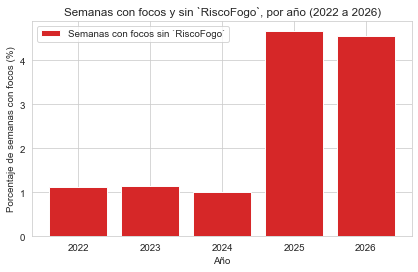

In [7]:
resumen_c = (
    con_focos.assign(sin_riesgo=con_focos["riesgo_fuego_promedio"].isna())
    .groupby("anio")
    .agg(semanas_con_focos=("num_incendios", "size"), sin_riesgo=("sin_riesgo", "sum"))
)
resumen_c["pct_sin_riesgo"] = resumen_c["sin_riesgo"] / resumen_c["semanas_con_focos"] * 100
print("(c) Semanas con focos pero sin riesgo calculado, por año:")
mostrar(resumen_c, 2)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(resumen_c.index.astype(str), resumen_c["pct_sin_riesgo"], color="tab:red", label="Semanas con focos sin `RiscoFogo`")
ax.set_title("Semanas con focos y sin `RiscoFogo`, por año (2022 a 2026)")
ax.set_xlabel("Año")
ax.set_ylabel("Porcentaje de semanas con focos (%)")
ax.legend()
plt.show()


**Figura 1.** Porcentaje de semanas con focos que no tienen `RiscoFogo` calculado, por año. Usa todas las semanas-municipio con focos de 2022 a 2026.


### Hallazgos de esta etapa

**Qué se observa**
- Hay **97,131** semanas-municipio sin focos (**71.3 %**). Es exactamente el número de nulos de `frp_promedio`, y en esas semanas el clima de BDQueimadas y el riesgo tienen **0** valores.
- Dentro de las semanas con focos, `RiscoFogo` falta en **1.12 %**, **1.13 %** y **1.00 %** (2022 a 2024), y sube a **4.66 %** en 2025 y **4.54 %** en 2026.
- En número de semanas con focos sin riesgo: **93**, **105**, **96**, **325** y **227** (2022 a 2026).
- `precipitacion_promedio` falta en **0.00 %** de las semanas con focos en 2022 a 2024, y en **3.81 %** (2025) y **4.06 %** (2026).
- Gráficos de apoyo: Figura 1.

**Por qué importa**
- Los nulos de focos son estructurales: significan "no hubo focos", no "dato perdido". Imputarlos crearía información falsa.
- El clima de BDQueimadas solo existe si ya hubo fuego esa semana, así que no sirve como predictora directa. El clima de las predictoras viene de NASA POWER, que no tiene nulos.

**Qué implica para Data Preparation y el modelado**
- Los nulos estructurales no se imputan. Las semanas sin `RiscoFogo` se excluyen del target de clasificación.
- **Limitación:** la falta de `RiscoFogo` es unas cuatro veces mayor en 2025 y 2026 (cerca de **4.6 %**) que en 2022 a 2024 (cerca de **1.1 %**). Hay que declararlo en el informe.


## 3. Variables objetivo

Se construyen los targets solo para explorarlos, con `groupby([municipio_norm, uf]).shift(-k)` sobre el panel ordenado y completo:
- `focos_t1`: focos de la semana siguiente.
- `focos_4s`: suma de los focos de las 4 semanas siguientes (nulo si faltan semanas, es decir, las últimas del panel).
- `clase_t` y `clase_t1`: clase de riesgo de la semana y de la siguiente, con los cortes 0.40, 0.70 y 0.95.

Se definen dos máscaras: `ENT` (semanas hasta 2024-12-30, para variables sin target) y `ENT_OBJ` (hasta 2024-12-02, para todo lo que use un target: así la ventana de 4 semanas no entra en 2025). Se muestran los targets por año (descriptivo) y se calcula el balance de clases y la persistencia de clase con `ENT_OBJ`.


In [8]:
CORTES_RIESGO = [-np.inf, 0.40, 0.70, 0.95, np.inf]
CLASES = ["Bajo", "Moderado", "Alto", "Crítico"]


def agregar_targets_exploratorios(panel):
    # targets solo para explorar; el panel debe estar completo (sin semanas faltantes por municipio)
    panel = panel.sort_values(CLAVE + ["semana"]).copy()
    pasos = panel.groupby(CLAVE)["semana"].diff().dropna()
    assert (pasos == pd.Timedelta(days=7)).all(), "Hay semanas faltantes: el shift no seria valido"

    g = panel.groupby(CLAVE)
    panel["focos_t1"] = g["num_incendios"].shift(-1)
    siguientes = pd.concat([g["num_incendios"].shift(-k) for k in range(1, 5)], axis=1)
    panel["focos_4s"] = siguientes.sum(axis=1, min_count=4)

    panel["clase_t"] = pd.cut(panel["riesgo_fuego_promedio"], CORTES_RIESGO, labels=CLASES)
    riesgo_siguiente = g["riesgo_fuego_promedio"].shift(-1)
    panel["clase_t1"] = pd.cut(riesgo_siguiente, CORTES_RIESGO, labels=CLASES)
    return panel


df = agregar_targets_exploratorios(df)

FIN_ENTRENO = pd.Timestamp("2024-12-30")
FIN_ENTRENO_OBJ = FIN_ENTRENO - pd.Timedelta(weeks=4)   # la ventana de 4 semanas termina en 2024
ENT = df["semana"] <= FIN_ENTRENO
ENT_OBJ = df["semana"] <= FIN_ENTRENO_OBJ

print("Filas ENT:", f"{ENT.sum():,}", "| filas ENT_OBJ:", f"{ENT_OBJ.sum():,}", "| ENT_OBJ hasta", FIN_ENTRENO_OBJ.date())
print("Nulos de focos_t1:", df["focos_t1"].isna().sum(), "| de focos_4s:", df["focos_4s"].isna().sum())


Filas ENT:

 85,251 | filas ENT_OBJ: 83,079 | ENT_OBJ hasta 2024-12-02
Nulos de focos_t1: 543 | de focos_4s: 2172


In [9]:
def resumen_target(serie, agrupador):
    return serie.groupby(agrupador).agg(
        filas="size",
        pct_ceros=lambda s: (s == 0).mean() * 100,
        media="mean",
        mediana="median",
        p95=lambda s: s.quantile(0.95),
        p99=lambda s: s.quantile(0.99),
        maximo="max",
    )


for objetivo in ["focos_t1", "focos_4s"]:
    valido = df[objetivo].notna()
    por_anio_t = resumen_target(df.loc[valido, objetivo], df.loc[valido, "anio"].astype(str))
    entreno = resumen_target(df.loc[ENT_OBJ, objetivo], pd.Series("2022-2024 (ENT_OBJ)", index=df.index[ENT_OBJ]))
    print(f"\n{objetivo} por año (descriptivo) y en entrenamiento:")
    mostrar(pd.concat([por_anio_t, entreno]), 2)



focos_t1 por año (descriptivo) y en entrenamiento:


                     filas  pct_ceros  media  mediana   p95   p99   maximo
2022                 28236      70.45   4.07     0.00 14.00 70.00 1,569.00
2023                 28236      67.15   3.50     0.00 15.00 59.00   773.00
2024                 28779      66.84   4.88     0.00 17.00 88.22 1,558.00
2025                 28236      74.94   1.56     0.00  8.00 27.00   208.00
2026                 22263      78.23   1.98     0.00  8.00 39.00   374.00
2022-2024 (ENT_OBJ)  83079      67.93   4.23     0.00 16.00 74.00 1,569.00

focos_4s por año (descriptivo) y en entrenamiento:
                     filas  pct_ceros  media  mediana   p95    p99   maximo
2022                 28236      49.57  16.26     1.00 56.00 257.00 3,883.00
2023                 28236      46.56  14.06     1.00 59.00 234.65 1,521.00
2024                 28779      46.27  19.47     1.00 69.00 329.88 5,044.00
2025                 28236      54.37   6.24     0.00 30.00  95.00   600.00
2026                 20634      62.17   7.

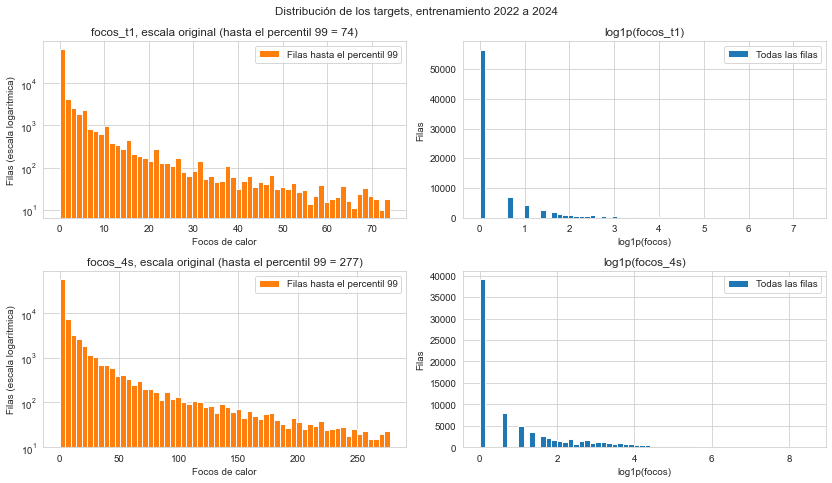

In [10]:
fig, ejes = plt.subplots(2, 2, figsize=(12, 7))
for fila, (objetivo, nombre) in enumerate([("focos_t1", "focos_t1"), ("focos_4s", "focos_4s")]):
    y = df.loc[ENT_OBJ, objetivo]
    tope = y.quantile(0.99)
    ejes[fila, 0].hist(y[y <= tope], bins=60, color="tab:orange", label="Filas hasta el percentil 99")
    ejes[fila, 0].set_yscale("log")
    ejes[fila, 0].set_title(f"{nombre}, escala original (hasta el percentil 99 = {tope:,.0f})")
    ejes[fila, 0].set_xlabel("Focos de calor")
    ejes[fila, 0].set_ylabel("Filas (escala logarítmica)")
    ejes[fila, 1].hist(np.log1p(y), bins=60, color="tab:blue", label="Todas las filas")
    ejes[fila, 1].set_title(f"log1p({nombre})")
    ejes[fila, 1].set_xlabel("log1p(focos)")
    ejes[fila, 1].set_ylabel("Filas")
    ejes[fila, 0].legend()
    ejes[fila, 1].legend()
plt.suptitle("Distribución de los targets, entrenamiento 2022 a 2024")
plt.tight_layout()
plt.show()


**Figura 2.** Histogramas de `focos_t1` y `focos_4s` en escala original (hasta el percentil 99, eje vertical logarítmico) y con `log1p`. Subconjunto `ENT_OBJ`, 2022 a 2024.


Clase de riesgo de la semana por año (conteo, solo semanas con riesgo calculado):
clase_t  Bajo  Moderado  Alto  Crítico
anio                                  
2022     4548      1226  1107     1344
2023     4725      1551  1504     1399
2024     3849      1433  1692     2518
2025     2777      1157  1351     1364
2026     1384      1069  1136     1182

Porcentaje por año:
clase_t  Bajo  Moderado  Alto  Crítico
anio                                  
2022     55.3      14.9  13.5     16.3
2023     51.5      16.9  16.4     15.2
2024     40.5      15.1  17.8     26.5
2025     41.8      17.4  20.3     20.5
2026     29.0      22.4  23.8     24.8

Balance de clases en entrenamiento (clase_t1, ENT_OBJ):
          filas  porcentaje
clase_t1                   
Bajo      12804        48.6
Moderado   4128        15.7
Alto       4221        16.0
Crítico    5198        19.7


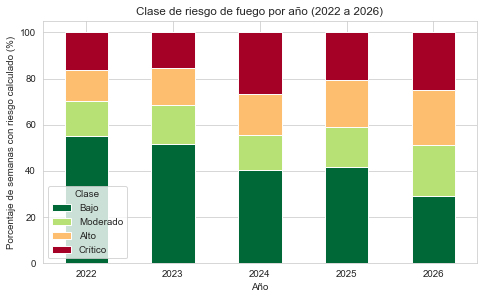

In [11]:
clase_anio = pd.crosstab(df["anio"], df["clase_t"])
print("Clase de riesgo de la semana por año (conteo, solo semanas con riesgo calculado):")
mostrar(clase_anio, 0)
print("\nPorcentaje por año:")
mostrar(clase_anio.div(clase_anio.sum(axis=1), axis=0) * 100, 1)

balance = df.loc[ENT_OBJ, "clase_t1"].value_counts().reindex(CLASES)
print("\nBalance de clases en entrenamiento (clase_t1, ENT_OBJ):")
mostrar(pd.DataFrame({"filas": balance, "porcentaje": balance / balance.sum() * 100}), 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
(clase_anio.div(clase_anio.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, ax=ax, colormap="RdYlGn_r")
ax.set_title("Clase de riesgo de fuego por año (2022 a 2026)")
ax.set_xlabel("Año")
ax.set_ylabel("Porcentaje de semanas con riesgo calculado (%)")
ax.legend(title="Clase")
plt.xticks(rotation=0)
plt.show()


**Figura 3.** Porcentaje de cada clase de riesgo (de la semana) por año, sobre las semanas-municipio con riesgo calculado. Usa todos los años.


Matriz de transición de la clase semana a semana (% por fila), entrenamiento:
clase_t1  Bajo  Moderado  Alto  Crítico
clase_t                                
Bajo      82.2      13.6   3.2      1.0
Moderado  28.9      40.8  25.6      4.7
Alto      11.9      18.6  47.3     22.1
Crítico    4.7       6.5  18.5     70.2

Pares con riesgo en ambas semanas: 18,017


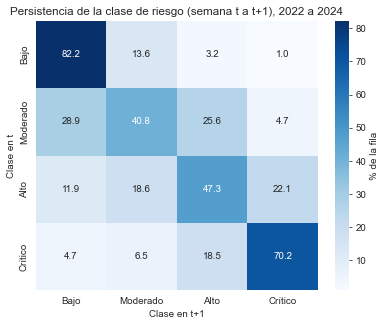

In [12]:
pares = df.loc[ENT_OBJ].dropna(subset=["clase_t", "clase_t1"])
transicion = pd.crosstab(pares["clase_t"], pares["clase_t1"], normalize="index") * 100
print("Matriz de transición de la clase semana a semana (% por fila), entrenamiento:")
mostrar(transicion, 1)
print(f"\nPares con riesgo en ambas semanas: {len(pares):,}")

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(transicion, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "% de la fila"})
ax.set_title("Persistencia de la clase de riesgo (semana t a t+1), 2022 a 2024")
ax.set_xlabel("Clase en t+1")
ax.set_ylabel("Clase en t")
plt.show()


**Figura 4.** Matriz de transición de la clase de riesgo de una semana a la siguiente, en porcentaje por fila. Subconjunto `ENT_OBJ`, 2022 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- En entrenamiento (`ENT_OBJ`, **83,079** filas), `focos_t1` es cero en **67.93 %** de las filas, con media **4.23**, mediana **0**, percentil 99 de **74** y máximo **1,569**. `focos_4s` es cero en **47.12 %**, con media **16.97**, mediana **1** y máximo **5,044**.
- Por año, el porcentaje de ceros de `focos_t1` es **70.45 %**, **67.15 %** y **66.84 %** (2022 a 2024), y sube a **74.94 %** (2025) y **78.23 %** (2026). La media baja de **4.88** (2024) a **1.56** y **1.98**.
- Clases de riesgo en entrenamiento (`clase_t1`): Bajo **48.6 %**, Moderado **15.7 %**, Alto **16.0 %** y Crítico **19.7 %**. La clase Crítico va de **16.3 %** (2022) y **15.2 %** (2023) a **26.5 %** (2024).
- La clase de la semana siguiente repite la actual en **82.2 %** (Bajo), **40.8 %** (Moderado), **47.3 %** (Alto) y **70.2 %** (Crítico) de los casos.
- Gráficos de apoyo: Figura 2, Figura 3 y Figura 4.

**Por qué importa**
- Los dos targets de regresión tienen mucha masa en cero y una cola extrema, por lo que el error medio lo dominan pocos casos.
- Las clases Moderado y Alto son las más escasas (alrededor de 16 % cada una) y también las más inestables entre semanas.

**Qué implica para Data Preparation y el modelado**
- Los targets de regresión se modelan con `log1p` (ver sección 6).
- **SMOTE** se justifica para las clases minoritarias, pero **solo dentro del entrenamiento** de cada partición de la validación cruzada, nunca en validación ni en prueba.
- **Limitación:** la proporción de Crítico cambia mucho entre años (15.2 % a 26.5 %), así que la prueba de 2025 no tendrá la misma mezcla de clases que el entrenamiento.


### Clase de riesgo por mes del año

Se calcula el porcentaje de cada clase de riesgo (de la semana, `clase_t`) por mes, con **2022 a 2024**, sobre las semanas-municipio que tienen riesgo calculado. El mes es el de la semana (su lunes). Sirve para ver en qué meses se concentra la clase Crítico y si coincide con la temporada seca (julio a noviembre).


In [13]:
clase_mes = pd.crosstab(df.loc[ENT, "mes"], df.loc[ENT, "clase_t"])
clase_mes_pct = clase_mes.div(clase_mes.sum(axis=1), axis=0) * 100
print("Semanas-municipio con riesgo calculado, por mes y clase (2022 a 2024):")
mostrar(clase_mes, 0)
print("\nPorcentaje de cada clase por mes:")
mostrar(clase_mes_pct, 1)

critico_temporada = pd.crosstab(df.loc[ENT, "temporada"], df.loc[ENT, "clase_t"])
print("\nPorcentaje de la clase Crítico que cae en cada temporada:")
mostrar((critico_temporada["Crítico"] / critico_temporada["Crítico"].sum() * 100).to_frame("pct_del_total_critico"), 1)
print("\nPorcentaje de Crítico dentro de cada temporada:")
mostrar((critico_temporada.div(critico_temporada.sum(axis=1), axis=0) * 100)[["Crítico"]], 1)


Semanas-municipio con riesgo calculado, por mes y clase (2022 a 2024):
clase_t  Bajo  Moderado  Alto  Crítico
mes                                   
1        1181        63    49       50
2         802        33    30       37
3         616        19    28       36
4         558        38    31       16
5         657       230   135       82
6         638       342   308      226
7         920       443   626      709
8        1078       654   592     1170
9        1241       779   902     1258
10       2066       743   829      897
11       1816       476   529      607
12       1549       390   244      173

Porcentaje de cada clase por mes:
clase_t  Bajo  Moderado  Alto  Crítico
mes                                   
1        87.9       4.7   3.6      3.7
2        88.9       3.7   3.3      4.1
3        88.1       2.7   4.0      5.2
4        86.8       5.9   4.8      2.5
5        59.5      20.8  12.2      7.4
6        42.1      22.6  20.3     14.9
7        34.1      16.4  23.2     26

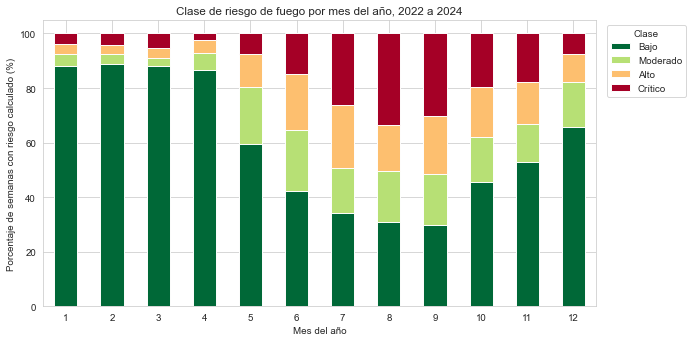

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
clase_mes_pct.plot(kind="bar", stacked=True, ax=ax, colormap="RdYlGn_r")
ax.set_title("Clase de riesgo de fuego por mes del año, 2022 a 2024")
ax.set_xlabel("Mes del año")
ax.set_ylabel("Porcentaje de semanas con riesgo calculado (%)")
ax.legend(title="Clase", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Figura 5.** Barras apiladas con el porcentaje de cada clase de riesgo por mes del año, sobre las semanas-municipio con riesgo calculado. Subconjunto `ENT`, 2022 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- La clase **Crítico** sube de **2.5 %** (abril) y **3.7 %** (enero) a **26.3 %** (julio), **33.5 %** (agosto) y **30.1 %** (septiembre), y baja a **19.8 %** (octubre), **17.7 %** (noviembre) y **7.3 %** (diciembre).
- La clase Bajo domina de enero a abril (de **86.8 %** a **88.9 %**) y cae a **29.7 %** en septiembre.
- El **88.2 %** de las semanas Crítico cae en temporada seca. Dentro de la seca, Crítico es **25.3 %** de las semanas con riesgo; en la húmeda, **7.2 %**.
- Gráficos de apoyo: Figura 5.

**Por qué importa**
- Crítico se concentra en agosto y septiembre y **coincide con la temporada seca** (julio a noviembre), aunque el pico no ocupa toda la temporada: octubre y noviembre ya bajan.
- La clase depende mucho de la época del año, así que un clasificador sin información de calendario aprendería sobre todo la estacionalidad.

**Qué implica para Data Preparation y el modelado**
- Se incluyen el mes o la temporada como predictoras del Frente 2.
- **Limitación:** el riesgo solo existe en semanas con focos y fuera de la temporada seca hay pocas semanas Crítico (por ejemplo **16** en abril), así que el modelo verá pocos ejemplos de esa clase en los meses húmedos.


## 4. Persistencia y baseline

Se mide cuánta información ya trae el valor actual. **Subconjunto:** `ENT_OBJ` (2022 a 2024 con margen de 4 semanas).
- Correlación de `num_incendios` con sus rezagos de 1 a 4 semanas (por municipio).
- Autocorrelación del total semanal de focos (suma de todos los municipios).
- Baseline de persistencia (`focos_t1 = focos_t`) y de promedio móvil de las últimas 4 semanas, con MAE y RMSE.
- Accuracy de la persistencia de clase (la clase de la semana siguiente es igual a la actual).

Esta sección fija el **piso que el modelo debe superar**.


In [15]:
agrupado = df.groupby(CLAVE)["num_incendios"]
rezagos = pd.DataFrame({f"rezago_{k}": agrupado.shift(k) for k in range(1, 5)})
rezagos.insert(0, "num_incendios", df["num_incendios"])

corr_rezagos = rezagos.loc[ENT].corr(method="pearson")["num_incendios"].drop("num_incendios")
corr_rezagos_sp = rezagos.loc[ENT].corr(method="spearman")["num_incendios"].drop("num_incendios")
print("Correlación de num_incendios con sus rezagos (2022 a 2024):")
mostrar(pd.DataFrame({"pearson": corr_rezagos, "spearman": corr_rezagos_sp}), 3)


Correlación de num_incendios con sus rezagos (2022 a 2024):
          pearson  spearman
rezago_1    0.780     0.628
rezago_2    0.640     0.594
rezago_3    0.488     0.568
rezago_4    0.382     0.541


Autocorrelación del total semanal de focos:
    autocorrelacion
1             0.888
2             0.752
3             0.633
4             0.505
5             0.402
6             0.319
7             0.222
8             0.133
9             0.089
10            0.054
11           -0.012
12           -0.065
Banda de confianza aproximada del 95 % si no hubiera autocorrelación: +/- 0.156


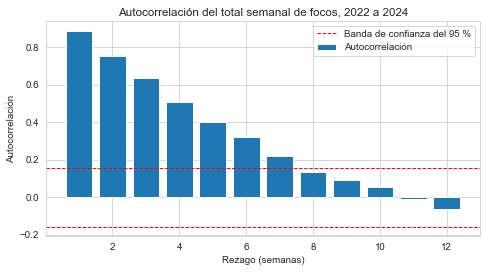

In [16]:
total_semanal = df.loc[ENT].groupby("semana")["num_incendios"].sum()
acf = pd.Series([total_semanal.autocorr(k) for k in range(1, 13)], index=range(1, 13))
banda = 1.96 / np.sqrt(len(total_semanal))
print("Autocorrelación del total semanal de focos:")
mostrar(acf.to_frame("autocorrelacion"), 3)
print(f"Banda de confianza aproximada del 95 % si no hubiera autocorrelación: +/- {banda:.3f}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(acf.index, acf.values, color="tab:blue", label="Autocorrelación")
ax.axhline(banda, color="red", linestyle="--", linewidth=1, label="Banda de confianza del 95 %")
ax.axhline(-banda, color="red", linestyle="--", linewidth=1)
ax.set_title("Autocorrelación del total semanal de focos, 2022 a 2024")
ax.set_xlabel("Rezago (semanas)")
ax.set_ylabel("Autocorrelación")
ax.legend()
plt.show()


**Figura 6.** Autocorrelación del total semanal de focos (suma de municipios) para rezagos de 1 a 12 semanas, con la banda de confianza aproximada. Subconjunto `ENT`.


In [17]:
def metricas_baseline(real, prediccion):
    error = real - prediccion
    return {"MAE": error.abs().mean(), "RMSE": float(np.sqrt((error ** 2).mean()))}


promedio_movil_4 = df.groupby(CLAVE)["num_incendios"].transform(lambda s: s.rolling(4).mean())
validos = ENT_OBJ & df["focos_t1"].notna() & promedio_movil_4.notna()

baselines = pd.DataFrame({
    "persistencia (focos_t)": metricas_baseline(df.loc[validos, "focos_t1"], df.loc[validos, "num_incendios"]),
    "promedio móvil 4 semanas": metricas_baseline(df.loc[validos, "focos_t1"], promedio_movil_4[validos]),
}).T
print(f"Baselines para focos_t1 en 2022 a 2024 ({validos.sum():,} filas):")
mostrar(baselines, 3)
print("Referencia: media de focos_t1 =", f"{df.loc[validos, 'focos_t1'].mean():.3f}", "| desviación estándar =", f"{df.loc[validos, 'focos_t1'].std():.3f}")

solo_con_focos = validos & (df["num_incendios"] > 0)
print(f"\nMismos baselines solo en semanas con focos en t ({solo_con_focos.sum():,} filas):")
mostrar(pd.DataFrame({
    "persistencia (focos_t)": metricas_baseline(df.loc[solo_con_focos, "focos_t1"], df.loc[solo_con_focos, "num_incendios"]),
    "promedio móvil 4 semanas": metricas_baseline(df.loc[solo_con_focos, "focos_t1"], promedio_movil_4[solo_con_focos]),
}).T, 3)


Baselines para focos_t1 en 2022 a 2024 (81,450 filas):
                           MAE   RMSE
persistencia (focos_t)   3.343 18.448
promedio móvil 4 semanas 3.703 21.878
Referencia: media de focos_t1 = 4.305 | desviación estándar = 27.826

Mismos baselines solo en semanas con focos en t (26,173 filas):
                            MAE   RMSE
persistencia (focos_t)    9.516 32.423
promedio móvil 4 semanas 10.330 38.471


In [18]:
acc_persistencia = (pares["clase_t"] == pares["clase_t1"]).mean()
clase_mayoritaria = pares["clase_t1"].value_counts(normalize=True)
print(f"Accuracy de persistencia de clase (clase_t1 = clase_t): {acc_persistencia * 100:.1f} %")
print(f"Referencia, predecir siempre la clase mayoritaria ({clase_mayoritaria.idxmax()}): {clase_mayoritaria.max() * 100:.1f} %")
print(f"Pares evaluados: {len(pares):,}")


Accuracy de persistencia de clase (clase_t1 = clase_t): 66.1 %
Referencia, predecir siempre la clase mayoritaria (Bajo): 44.4 %
Pares evaluados: 18,017


### Hallazgos de esta etapa

**Qué se observa**
- La correlación de Pearson de `num_incendios` con su rezago baja de **0.780** (1 semana) a **0.640**, **0.488** y **0.382** (4 semanas). Con Spearman va de **0.628** a **0.541**.
- La autocorrelación del total semanal es **0.888** (rezago 1), **0.752**, **0.633** y **0.505** (rezago 4), y entra en la banda de ruido (+/- **0.156**) desde el rezago 8 (**0.133**).
- El baseline de persistencia (`focos_t1 = focos_t`) da **MAE 3.343** y **RMSE 18.448**. El promedio móvil de 4 semanas es peor: **3.703** y **21.878**. La desviación estándar de `focos_t1` es **27.826**.
- Solo en semanas con focos en `t`, la persistencia da **MAE 9.516** y **RMSE 32.423**.
- La persistencia de clase acierta **66.1 %**, frente a **44.4 %** de predecir siempre la clase Bajo.
- Gráficos de apoyo: Figura 6.

**Por qué importa**
- El valor de esta semana ya explica gran parte de la siguiente. Ese es el piso que el modelo tiene que superar.
- El MAE global parece bajo porque **67.93 %** de las filas son cero. El MAE de las semanas con focos (**9.516**) es más exigente.

**Qué implica para Data Preparation y el modelado**
- Se construyen rezagos de 1 a 4 semanas de `num_incendios`. Los modelos se comparan contra **MAE 3.343**, **RMSE 18.448** y **66.1 %** de accuracy.
- **Limitación:** se reportarán las métricas tanto globales como solo en semanas con focos.


## 5. Valores atípicos

Se usan boxplots y la regla IQR (límites en Q1 - 1.5 IQR y Q3 + 1.5 IQR), calculada **solo con 2022 a 2024 (`ENT`)**. Se compara el porcentaje de valores fuera de rango con la regla de **3 desviaciones estándar**. Para `num_incendios` y `frp_total` la mayoría de las filas vale cero, así que el IQR es muy estrecho y casi todo valor positivo queda como atípico: por eso también se reporta la regla sobre las filas con focos. Luego se listan los casos extremos con su contexto.


### Técnicas usadas

- **Regla del rango intercuartílico (IQR):** marca como atípico lo que queda fuera de Q1 menos 1.5 IQR y Q3 más 1.5 IQR. No supone ninguna forma de la distribución, así que es adecuada cuando la variable **no es normal**.
- **Regla de 3 desviaciones estándar:** marca lo que queda a más de 3 desviaciones de la media. Usa la media y la desviación, que se distorsionan con colas largas, así que solo es razonable si la variable es **aproximadamente normal**.
- **Cómo se elige:** IQR si la variable no es normal y 3 desviaciones estándar si es aproximadamente normal. La normalidad se evalúa en la sección 6 (asimetría, curtosis y gráficos Q-Q) y allí se fija la tabla "Criterio de atípicos por variable". Es decir, **la normalidad se evalúa antes de tratar los atípicos en Data Preparation**.
- **En esta sección** se calculan ambas reglas para comparar cuántos casos marca cada una, se dibujan boxplots y se listan los casos extremos con su contexto.


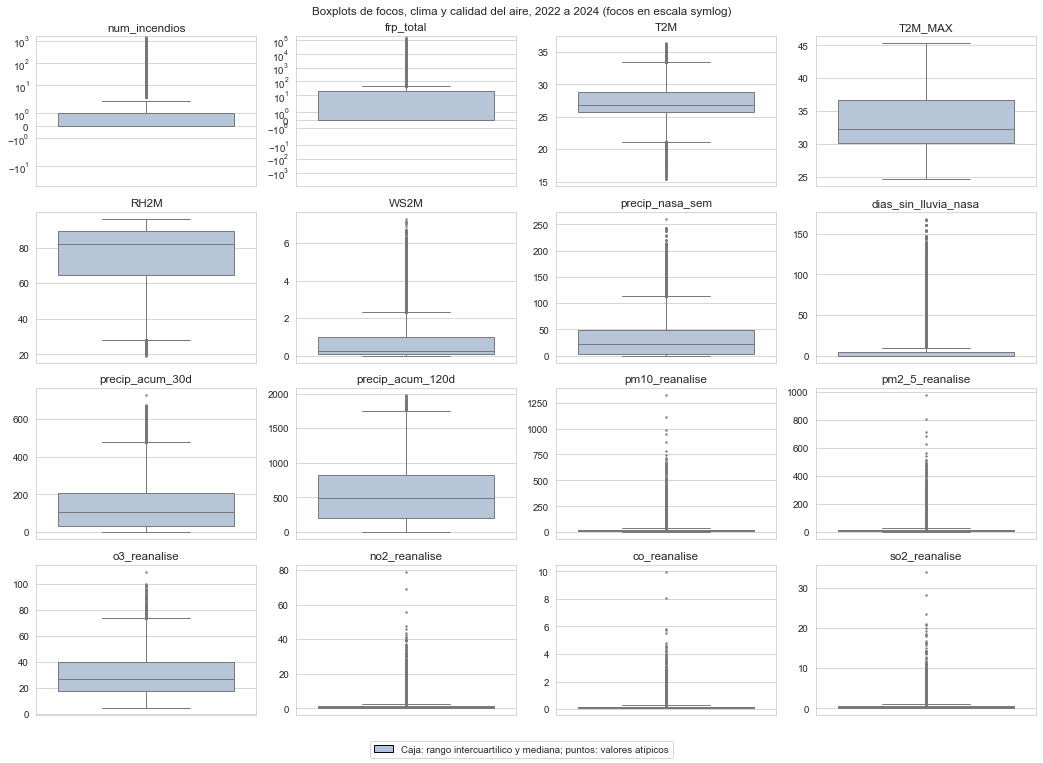

In [19]:
VARS_ATIPICOS = ["num_incendios", "frp_total", "T2M", "T2M_MAX", "RH2M", "WS2M", "precip_nasa_sem",
                 "dias_sin_lluvia_nasa", "precip_acum_30d", "precip_acum_120d",
                 "pm10_reanalise", "pm2_5_reanalise", "o3_reanalise", "no2_reanalise", "co_reanalise", "so2_reanalise"]

fig, ejes = plt.subplots(4, 4, figsize=(15, 11))
for eje, variable in zip(ejes.ravel(), VARS_ATIPICOS):
    sns.boxplot(y=df.loc[ENT, variable], ax=eje, color="lightsteelblue", fliersize=1.5)
    if variable in ("num_incendios", "frp_total"):
        eje.set_yscale("symlog")
    eje.set_title(variable)
    eje.set_ylabel("")
fig.legend(handles=[Patch(facecolor="lightsteelblue", edgecolor="k", label="Caja: rango intercuartílico y mediana; puntos: valores atípicos")], loc="lower center")
plt.suptitle("Boxplots de focos, clima y calidad del aire, 2022 a 2024 (focos en escala symlog)")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()


**Figura 7.** Boxplots de 16 variables numéricas con la distribución de todas las filas de 2022 a 2024 (`ENT`). Los focos usan escala symlog para poder verse.


In [20]:
def tabla_atipicos(datos, variables):
    filas = []
    for variable in variables:
        x = datos[variable].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        fuera_iqr = ((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).mean() * 100
        media, desvio = x.mean(), x.std()
        fuera_3sd = ((x < media - 3 * desvio) | (x > media + 3 * desvio)).mean() * 100
        filas.append({"variable": variable, "q1": q1, "q3": q3, "limite_sup_iqr": q3 + 1.5 * iqr,
                      "pct_fuera_iqr": fuera_iqr, "pct_fuera_3sd": fuera_3sd})
    return pd.DataFrame(filas).set_index("variable")


tabla_a = tabla_atipicos(df[ENT], VARS_ATIPICOS)
print("Valores fuera de rango, 2022 a 2024 (todas las filas):")
mostrar(tabla_a, 2)

solo_focos = df[ENT & (df["num_incendios"] > 0)]
print(f"\nSolo semanas con focos ({len(solo_focos):,} filas):")
mostrar(tabla_atipicos(solo_focos, ["num_incendios", "frp_total"]), 2)


Valores fuera de rango, 2022 a 2024 (todas las filas):
                         q1     q3  limite_sup_iqr  pct_fuera_iqr  pct_fuera_3sd
variable                                                                        
num_incendios          0.00   1.00            2.50          18.37           0.81
frp_total              0.00  20.20           50.50          18.96           0.61
T2M                   25.75  28.83           33.44           1.09           0.43
T2M_MAX               30.06  36.72           46.71           0.00           0.00
RH2M                  64.73  89.19          125.87           0.36           0.15
WS2M                   0.08   0.97            2.31           3.50           1.57
precip_nasa_sem        3.78  47.94          114.18           2.62           1.46
dias_sin_lluvia_nasa   0.00   4.00           10.00          15.27           2.98
precip_acum_30d       29.39 209.50          479.67           0.88           0.70
precip_acum_120d     206.82 827.23        1,757.85    

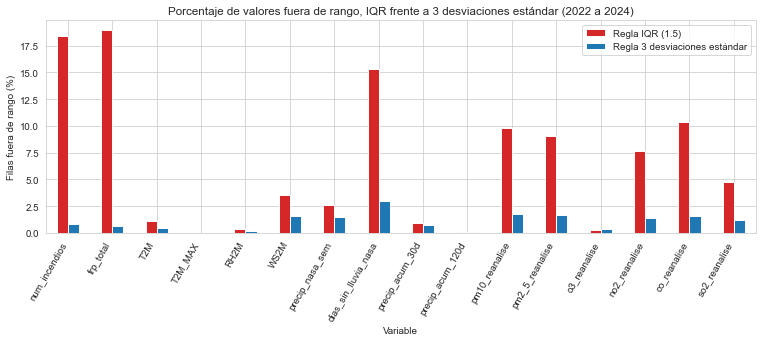

In [21]:
fig, ax = plt.subplots(figsize=(11, 5))
tabla_a[["pct_fuera_iqr", "pct_fuera_3sd"]].plot(kind="bar", ax=ax, color=["tab:red", "tab:blue"])
ax.set_title("Porcentaje de valores fuera de rango, IQR frente a 3 desviaciones estándar (2022 a 2024)")
ax.set_xlabel("Variable")
ax.set_ylabel("Filas fuera de rango (%)")
ax.legend(["Regla IQR (1.5)", "Regla 3 desviaciones estándar"])
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


**Figura 8.** Comparación del porcentaje de filas fuera de rango según la regla IQR y la regla de 3 desviaciones estándar, por variable. Subconjunto `ENT`, 2022 a 2024.


In [22]:
columnas_caso = ["municipio_norm", "uf", "semana", "num_incendios", "frp_total"]
print("10 mayores valores de num_incendios (2022 a 2024):")
extremos = df.loc[ENT, columnas_caso].nlargest(10, "num_incendios").reset_index(drop=True)
mostrar(extremos, 1)

print("\n10 mayores valores de frp_total (2022 a 2024):")
mostrar(df.loc[ENT, columnas_caso].nlargest(10, "frp_total").reset_index(drop=True), 1)

top_100 = df.loc[ENT, columnas_caso + ["anio"]].nlargest(100, "num_incendios")
print("\nContexto: los 100 mayores valores de num_incendios por estado y año:")
mostrar(pd.crosstab(top_100["uf"], top_100["anio"]), 0)
print("\nMunicipios con más casos entre esos 100:")
print(top_100.groupby(CLAVE).size().sort_values(ascending=False).head(8).to_string())


10 mayores valores de num_incendios (2022 a 2024):
       municipio_norm  uf     semana  num_incendios  frp_total
0  SAO FELIX DO XINGU  PA 2022-08-29           1569  100,728.3
1  SAO FELIX DO XINGU  PA 2024-09-02           1558   79,349.0
2  SAO FELIX DO XINGU  PA 2024-08-26           1515  110,606.2
3            ALTAMIRA  PA 2024-09-02           1413  148,665.8
4            ALTAMIRA  PA 2022-08-29           1356  119,834.6
5            ALTAMIRA  PA 2024-08-26           1132   93,521.3
6  SAO FELIX DO XINGU  PA 2022-08-15           1131   64,118.8
7            ALTAMIRA  PA 2022-08-15           1098   94,166.6
8      NOVO PROGRESSO  PA 2024-09-02           1048   92,923.4
9  SAO FELIX DO XINGU  PA 2024-09-09           1027   51,116.2

10 mayores valores de frp_total (2022 a 2024):
       municipio_norm  uf     semana  num_incendios  frp_total
0                APUI  AM 2024-07-29            989  198,186.2
1            ALTAMIRA  PA 2024-09-02           1413  148,665.8
2              LABR

### Hallazgos de esta etapa

**Qué se observa**
- En `num_incendios` la regla IQR marca **18.37 %** de las filas como atípicas (límite superior **2.50**), frente a **0.81 %** con 3 desviaciones estándar. En `frp_total` son **18.96 %** y **0.61 %**.
- Entre las semanas con focos, las cifras bajan a **11.40 %** (IQR) y **1.18 %** (3 desviaciones estándar) en `num_incendios`.
- En clima y calidad del aire, el IQR marca más que 3 desviaciones estándar: `dias_sin_lluvia_nasa` **15.27 %** frente a **2.98 %**, `co_reanalise` **10.40 %** frente a **1.55 %** y `pm10_reanalise` **9.83 %** frente a **1.71 %**. `T2M_MAX` marca **0.00 %** con ambas.
- El mayor valor es **1,569 focos** en `SAO FELIX DO XINGU` (PA), semana del 2022-08-29. De los 100 mayores valores, **26** son de Pará en 2024, y `ALTAMIRA` (**15**) y `SAO FELIX DO XINGU` (**12**) son los municipios más repetidos.
- Gráficos de apoyo: Figura 7 y Figura 8.

**Por qué importa**
- Los extremos de focos son picos reales de agosto y septiembre en el sur de Pará y en Amazonas, no errores de medición. Borrarlos eliminaría justo los casos que interesa predecir.
- Con tantos ceros, el IQR queda muy estrecho (Q1 = **0**, Q3 = **1**) y marca casi un quinto de las filas.

**Qué implica para Data Preparation y el modelado**
- No se eliminan ni se recortan filas de focos ni de `frp_total`: se transforman con `log1p`.
- Los límites de cualquier recorte en clima y calidad del aire se calculan solo con 2022 a 2024. El criterio por variable (IQR o 3 desviaciones estándar) se fija en la sección 6, según la normalidad.


## 6. Prueba de normalidad (D'Agostino-Pearson)

Se aplica `scipy.stats.normaltest` a los targets y a las variables continuas, en escala original y con `log1p`, **solo con 2022 a 2024**. Con más de 100,000 filas, la prueba rechaza la normalidad casi siempre por mínimas desviaciones, así que **un resultado significativo no es informativo por sí solo**. Por eso se usan además la asimetría, la curtosis y los gráficos Q-Q para decidir entre IQR y 3 desviaciones estándar. La regla de 3 desviaciones estándar solo es razonable si la variable es aproximadamente normal.


### Técnicas usadas

- **Prueba de D'Agostino-Pearson (`scipy.stats.normaltest`):** combina la asimetría y la curtosis en un solo estadístico y es apropiada para muestras grandes. **No se usa Shapiro-Wilk**, porque pierde validez con decenas de miles de filas.
- **Asimetría y curtosis:** miden cuánto se aleja la forma de la distribución de una normal. En la normal la asimetría es 0 y la curtosis en exceso también es 0.
- **Gráficos Q-Q:** comparan los cuantiles observados con los de una normal. Si los puntos siguen la recta, la variable es aproximadamente normal.
- **Escala original y `log1p`:** todo se repite con `log1p`, para ver si la transformación acerca la variable a la normal.
- **Por qué no basta la prueba formal:** con tantas filas, la prueba detecta diferencias mínimas y rechaza la normalidad casi siempre. Por eso la decisión se apoya también en la asimetría, la curtosis y los gráficos Q-Q.


In [23]:
VARS_NORMALIDAD = ["focos_t1", "focos_4s", "num_incendios", "frp_total", "T2M", "T2M_MAX", "RH2M", "WS2M", "precip_nasa_sem",
                   "dias_sin_lluvia_nasa", "precip_acum_30d", "precip_acum_120d",
                   "pm10_reanalise", "pm2_5_reanalise", "o3_reanalise", "no2_reanalise", "co_reanalise", "so2_reanalise"]


def prueba_normalidad(serie):
    x = serie.dropna()
    assert (x >= 0).all(), "log1p requiere valores no negativos"
    estadistico, p = stats.normaltest(x)
    return {"estadistico": estadistico, "p_valor": p, "asimetria": stats.skew(x), "curtosis": stats.kurtosis(x)}


filas = []
for variable in VARS_NORMALIDAD:
    base = df.loc[ENT_OBJ, variable]
    original = prueba_normalidad(base)
    transformada = prueba_normalidad(np.log1p(base))
    filas.append({"variable": variable, "asim_original": original["asimetria"], "curt_original": original["curtosis"],
                  "p_original": original["p_valor"], "asim_log1p": transformada["asimetria"],
                  "curt_log1p": transformada["curtosis"], "p_log1p": transformada["p_valor"]})
tabla_normalidad = pd.DataFrame(filas).set_index("variable")
print(f"D'Agostino-Pearson con {ENT_OBJ.sum():,} filas (2022 a 2024):")
print(tabla_normalidad.to_string(float_format=lambda v: f"{v:,.3f}" if abs(v) >= 0.001 else f"{v:.1e}"))
print("\nVariables con p < 0.05 en escala original:", int((tabla_normalidad["p_original"] < 0.05).sum()), "de", len(tabla_normalidad))
print("Variables con p < 0.05 con log1p:", int((tabla_normalidad["p_log1p"] < 0.05).sum()), "de", len(tabla_normalidad))


D'Agostino-Pearson con 83,079 filas (2022 a 2024):
                      asim_original  curt_original  p_original  asim_log1p  curt_log1p  p_log1p
variable                                                                                       
focos_t1                     24.673        921.780     0.0e+00       2.140       4.735  0.0e+00
focos_4s                     20.607        636.048     0.0e+00       1.261       1.024  0.0e+00
num_incendios                24.679        922.084     0.0e+00       2.152       4.795  0.0e+00
frp_total                    30.229      1,378.048     0.0e+00       1.382       0.762  0.0e+00
T2M                           0.560          0.349     0.0e+00       0.275       0.736  0.0e+00
T2M_MAX                       0.529         -1.026     0.0e+00       0.419      -1.162  0.0e+00
RH2M                         -0.973         -0.078     0.0e+00      -1.462       1.704  0.0e+00
WS2M                          1.993          5.848     0.0e+00       0.982       0.08

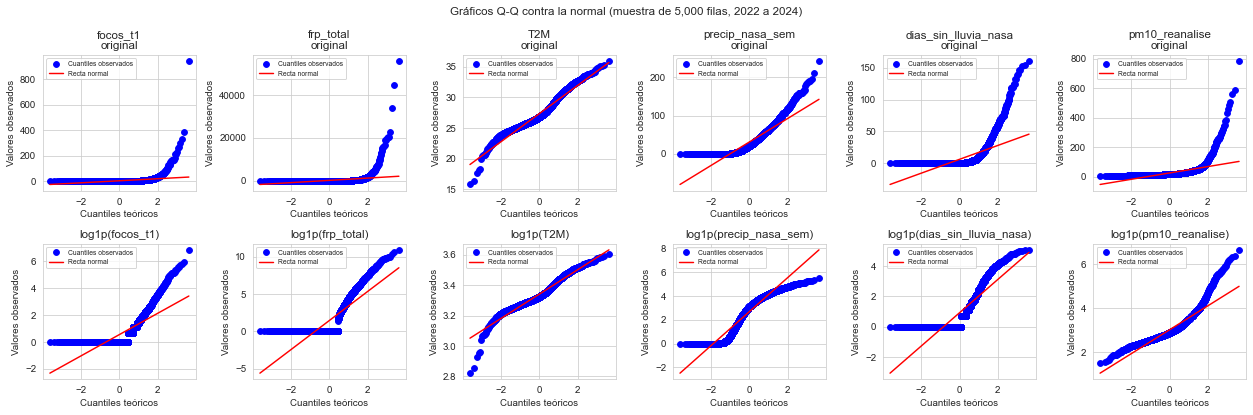

In [24]:
VARS_QQ = ["focos_t1", "frp_total", "T2M", "precip_nasa_sem", "dias_sin_lluvia_nasa", "pm10_reanalise"]
muestra_qq = df.loc[ENT_OBJ].sample(5000, random_state=ALEATORIO)

fig, ejes = plt.subplots(2, 6, figsize=(18, 6))
for columna, variable in enumerate(VARS_QQ):
    x = muestra_qq[variable].dropna()
    stats.probplot(x, dist="norm", plot=ejes[0, columna])
    ejes[0, columna].set_title(f"{variable}\noriginal")
    stats.probplot(np.log1p(x), dist="norm", plot=ejes[1, columna])
    ejes[1, columna].set_title(f"log1p({variable})")
    for fila_qq in (0, 1):
        lineas = ejes[fila_qq, columna].get_lines()
        lineas[0].set_label("Cuantiles observados")
        lineas[1].set_label("Recta normal")
        ejes[fila_qq, columna].legend(fontsize=7)
for eje in ejes.ravel():
    eje.set_xlabel("Cuantiles teóricos")
    eje.set_ylabel("Valores observados")
plt.suptitle("Gráficos Q-Q contra la normal (muestra de 5,000 filas, 2022 a 2024)")
plt.tight_layout()
plt.show()


**Figura 9.** Gráficos Q-Q de seis variables en escala original (fila superior) y con `log1p` (fila inferior). Muestra de 5,000 filas de `ENT_OBJ`.


### Criterio de atípicos por variable

La normalidad se evalúa **antes** de tratar los valores atípicos. Regla práctica: una variable se considera aproximadamente normal si, en escala original y con 2022 a 2024, su **asimetría está entre -0.6 y 0.6** y su **curtosis en exceso entre -1.5 y 1.5**. En ese caso se usa la regla de 3 desviaciones estándar. En cualquier otro caso, la regla del IQR. **Este es el criterio que se aplica en Data Preparation.**


In [25]:
def criterio_atipicos(asimetria, curtosis):
    # aproximadamente normal: asimetria y curtosis en exceso cercanas a 0
    return "3 desviaciones estándar" if abs(asimetria) <= 0.6 and abs(curtosis) <= 1.5 else "IQR"


tabla_criterio = tabla_normalidad[["asim_original", "curt_original"]].rename(
    columns={"asim_original": "asimetria", "curt_original": "curtosis"})
tabla_criterio["criterio"] = [criterio_atipicos(a, c) for a, c in zip(tabla_criterio["asimetria"], tabla_criterio["curtosis"])]
print("Criterio de atípicos por variable (2022 a 2024, escala original):")
mostrar(tabla_criterio, 3)
print("\nVariables con criterio de 3 desviaciones estándar:", list(tabla_criterio.index[tabla_criterio["criterio"] != "IQR"]))
print("Variables con criterio IQR:", int((tabla_criterio["criterio"] == "IQR").sum()), "de", len(tabla_criterio))


Criterio de atípicos por variable (2022 a 2024, escala original):
                      asimetria  curtosis                 criterio
variable                                                          
focos_t1                 24.673   921.780                      IQR
focos_4s                 20.607   636.048                      IQR
num_incendios            24.679   922.084                      IQR
frp_total                30.229 1,378.048                      IQR
T2M                       0.560     0.349  3 desviaciones estándar
T2M_MAX                   0.529    -1.026  3 desviaciones estándar
RH2M                     -0.973    -0.078                      IQR
WS2M                      1.993     5.848                      IQR
precip_nasa_sem           1.425     2.245                      IQR
dias_sin_lluvia_nasa      3.867    18.061                      IQR
precip_acum_30d           0.924     0.353                      IQR
precip_acum_120d          0.541    -0.550  3 desviaciones están

### Hallazgos de esta etapa

**Qué se observa**
- La prueba de D'Agostino-Pearson da **p menor a 0.05 en las 18 variables**, tanto en escala original como con `log1p`.
- `log1p` reduce mucho la asimetría de los focos: `focos_t1` de **24.673** a **2.140**, `frp_total` de **30.229** a **1.382** y `pm10_reanalise` de **8.653** a **1.655**.
- Algunas variables no mejoran: `RH2M` pasa de **-0.973** a **-1.462** y `precip_acum_120d` de **0.541** a **-1.178**. `co_reanalise` sigue con curtosis **36.141** tras `log1p`.
- Casi simétricas en escala original: `T2M` (**0.560**), `T2M_MAX` (**0.529**), `precip_acum_120d` (**0.541**) y `o3_reanalise` (**0.591**).
- Con la regla práctica de la tabla "Criterio de atípicos por variable" (asimetría entre -0.6 y 0.6 y curtosis entre -1.5 y 1.5), **4** variables quedan con 3 desviaciones estándar (`T2M`, `T2M_MAX`, `precip_acum_120d` y `o3_reanalise`) y **14 de 18** con IQR.
- Gráficos de apoyo: Figura 9.

**Por qué importa**
- Con 83,079 filas, la prueba rechaza la normalidad por diferencias mínimas: **que todas sean significativas no es informativo**. Por eso se decide con la asimetría, la curtosis y los gráficos Q-Q.
- La regla de 3 desviaciones estándar solo es razonable en variables cercanas a la normal.

**Qué implica para Data Preparation y el modelado**
- Se usa `log1p` en los targets, `frp_total`, los contaminantes de SISAM, `dias_sin_lluvia_nasa`, `WS2M` y `precip_nasa_sem`. No se usa en `T2M`, `RH2M` ni en los acumulados de precipitación.
- La normalidad se evaluó **antes** de tratar los atípicos. El criterio que se aplica en Data Preparation es **3 desviaciones estándar** para `T2M`, `T2M_MAX`, `precip_acum_120d` y `o3_reanalise`, e **IQR** para las otras **14** variables.


## 7. Evolución temporal

Se miran el total semanal de focos con los años superpuestos (eje x: semana del año), el perfil mensual y por temporada (seca de julio a noviembre, húmeda el resto) y la **variación interanual por estado y mes**, que es la base del KPI de variación interanual (referencia de 40 %). El mes de una semana es el mes de su lunes. **Subconjunto:** los años superpuestos y la variación interanual usan todos los años (es descripción y KPI); el perfil mensual y por temporada usa solo 2022 a 2024.


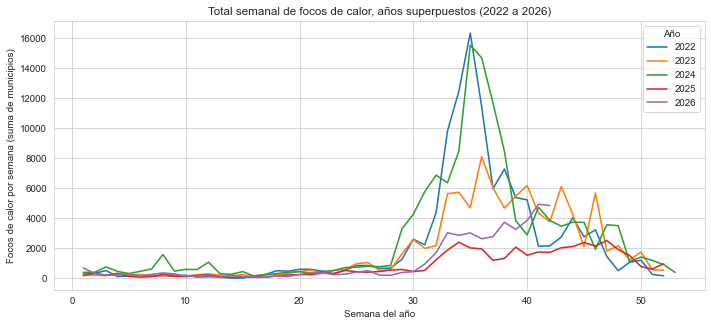

Total anual de focos (suma de municipios; 2026 llega solo hasta la semana 42):
       focos
anio        
2022  115022
2023   98620
2024  140656
2025   43525
2026   44769


In [26]:
semanal_total = df.groupby(["anio", "sem_anio"])["num_incendios"].sum().unstack("anio")

fig, ax = plt.subplots(figsize=(12, 5))
for anio in semanal_total.columns:
    ax.plot(semanal_total.index, semanal_total[anio], label=str(anio), linewidth=1.6)
ax.set_title("Total semanal de focos de calor, años superpuestos (2022 a 2026)")
ax.set_xlabel("Semana del año")
ax.set_ylabel("Focos de calor por semana (suma de municipios)")
ax.legend(title="Año")
plt.show()

print("Total anual de focos (suma de municipios; 2026 llega solo hasta la semana 42):")
mostrar(df.groupby("anio")["num_incendios"].sum().to_frame("focos"), 0)


**Figura 10.** Total semanal de focos (suma de municipios) con cada año como una línea, según la semana del año. Usa todas las semanas; 2026 llega hasta la semana 42.


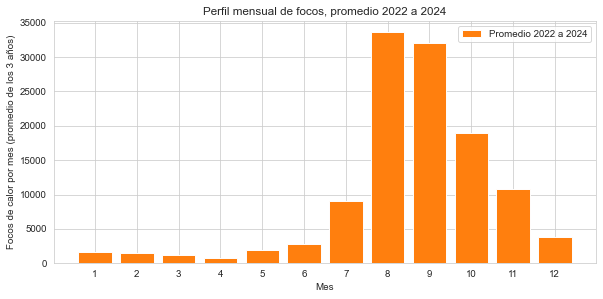

Focos por mes y año, 2022 a 2024:
anio   2022   2023   2024  promedio
mes                                
1      1335   1148   2257     1,580
2       526    827   3094     1,482
3       409    839   2509     1,252
4       384    744   1336       821
5      2578   1848   1575     2,000
6      2479   3080   2718     2,759
7      5165   7238  14907     9,103
8     45249  18220  37271    33,580
9     30091  24270  41579    31,980
10    16260  24636  15762    18,886
11     7909  11746  12700    10,785
12     2637   4024   4948     3,870

Por temporada (2022 a 2024):
           semanas_municipio   focos  media_focos  pct_semanas_con_focos  pct_del_total_de_focos
temporada                                                                                       
humeda                 49413   41295         0.84                  17.68                   11.66
seca                   35838  313003         8.73                  51.49                   88.34


In [27]:
mensual = df[ENT].groupby(["anio", "mes"])["num_incendios"].sum().unstack("anio")
mensual["promedio"] = mensual.mean(axis=1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(mensual.index, mensual["promedio"], color="tab:orange", label="Promedio 2022 a 2024")
ax.set_title("Perfil mensual de focos, promedio 2022 a 2024")
ax.set_xlabel("Mes")
ax.set_ylabel("Focos de calor por mes (promedio de los 3 años)")
ax.set_xticks(range(1, 13))
ax.legend()
plt.show()

print("Focos por mes y año, 2022 a 2024:")
mostrar(mensual, 0)

por_temporada = df[ENT].groupby("temporada").agg(
    semanas_municipio=("num_incendios", "size"),
    focos=("num_incendios", "sum"),
    media_focos=("num_incendios", "mean"),
    pct_semanas_con_focos=("num_incendios", lambda s: (s > 0).mean() * 100),
)
por_temporada["pct_del_total_de_focos"] = por_temporada["focos"] / por_temporada["focos"].sum() * 100
print("\nPor temporada (2022 a 2024):")
mostrar(por_temporada, 2)


**Figura 11.** Focos por mes, promediados sobre los tres años de entrenamiento. Subconjunto `ENT`, 2022 a 2024.


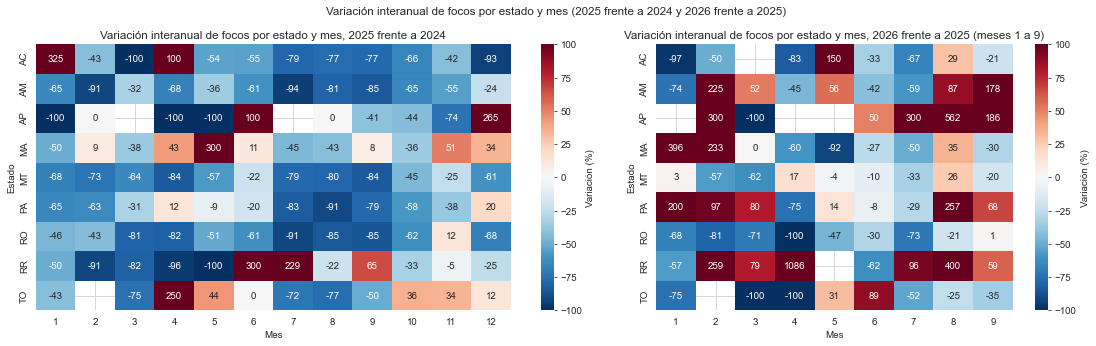

2025 frente a 2024: 108 celdas estado-mes | con variación menor a -40 %: 65 | mayor a +40 %: 12 | dentro de +/-40 %: 28
2026 frente a 2025: 81 celdas estado-mes | con variación menor a -40 %: 27 | mayor a +40 %: 25 | dentro de +/-40 %: 23


In [28]:
def variacion_interanual(panel, anio, anio_ref, meses):
    # variacion porcentual de focos por estado y mes frente al mismo mes del año de referencia
    total = panel.groupby(["uf", "anio", "mes"])["num_incendios"].sum()
    actual = total.xs(anio, level="anio")
    previo = total.xs(anio_ref, level="anio")
    variacion = (actual / previo.where(previo > 0) - 1) * 100
    return variacion.unstack("mes").reindex(columns=meses)


var_2025 = variacion_interanual(df, 2025, 2024, list(range(1, 13)))
var_2026 = variacion_interanual(df, 2026, 2025, list(range(1, 10)))

fig, ejes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [12, 9]})
for eje, tabla, titulo in [(ejes[0], var_2025, "2025 frente a 2024"), (ejes[1], var_2026, "2026 frente a 2025 (meses 1 a 9)")]:
    sns.heatmap(tabla, annot=True, fmt=".0f", cmap="RdBu_r", center=0, vmin=-100, vmax=100, ax=eje,
                cbar_kws={"label": "Variación (%)"})
    eje.set_title(f"Variación interanual de focos por estado y mes, {titulo}")
    eje.set_xlabel("Mes")
    eje.set_ylabel("Estado")
fig.suptitle("Variación interanual de focos por estado y mes (2025 frente a 2024 y 2026 frente a 2025)")
plt.tight_layout()
plt.show()

for nombre, tabla in [("2025 frente a 2024", var_2025), ("2026 frente a 2025", var_2026)]:
    valores = tabla.stack()
    print(f"{nombre}: {len(valores)} celdas estado-mes | con variación menor a -40 %: {(valores < -40).sum()} | mayor a +40 %: {(valores > 40).sum()} | dentro de +/-40 %: {valores.between(-40, 40).sum()}")


**Figura 12.** Variación porcentual de los focos por estado y mes frente al mismo mes del año anterior (a la izquierda 2025 frente a 2024; a la derecha 2026 frente a 2025, meses 1 a 9). Es descriptivo y usa todos los años.


### Hallazgos de esta etapa

**Qué se observa**
- Total anual de focos: **115,022** (2022), **98,620** (2023), **140,656** (2024), **43,525** (2025) y **44,769** (2026, hasta la semana 42).
- En 2022 a 2024, agosto (**33,580**) y septiembre (**31,980**) concentran el pico; abril tiene **821**. La temporada seca (julio a noviembre) reúne **88.34 %** de los focos y tiene focos en **51.49 %** de las semanas-municipio, frente a **17.68 %** de la húmeda.
- En 2024 julio tuvo **14,907** focos, contra **5,165** (2022) y **7,238** (2023).
- La variación interanual de 2025 frente a 2024 fue menor a -40 % en **65** de **108** celdas estado-mes, y mayor a +40 % en **12**. En 2026 frente a 2025: **27** de **81** por debajo de -40 % y **25** por encima de +40 %.
- Gráficos de apoyo: Figura 10, Figura 11 y Figura 12.

**Por qué importa**
- La estacionalidad es muy fuerte: el modelo debe saber en qué época del año está.
- Con la referencia de 40 %, el KPI de variación interanual marcaría la mayoría de las celdas en 2025 (**65** de **108** cayeron más de 40 %) por la caída general de los focos.

**Qué implica para Data Preparation y el modelado**
- Se incluyen variables de calendario (mes o semana del año y temporada).
- **Limitación:** la variación interanual depende del año base; en 2025 y 2026 la comparación incluye un cambio de nivel, no solo del municipio.


## 8. Distribución espacial

Focos por estado, los 15 municipios con más focos, el porcentaje concentrado en los 10 primeros y un mapa de dispersión con `lat` y `lon` (un punto por municipio; tamaño y color según el total de focos). **Subconjunto:** 2022 a 2024. Las coordenadas son los centroides fijos de los focos de cada municipio.


Focos por estado, 2022 a 2024:
     focos  porcentaje
uf                    
PA  139344        39.3
AM   66315        18.7
MT   59103        16.7
RO   30560         8.6
AC   27061         7.6
MA   15634         4.4
RR    9262         2.6
AP    5559         1.6
TO    1460         0.4


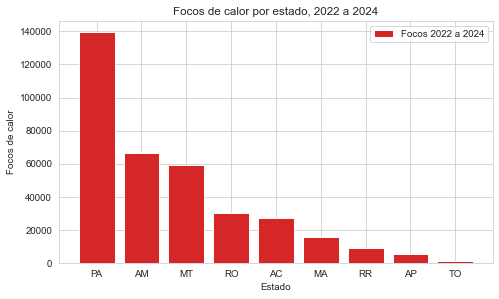

In [29]:
focos_estado = df[ENT].groupby("uf")["num_incendios"].sum().sort_values(ascending=False)
tabla_estado = pd.DataFrame({"focos": focos_estado, "porcentaje": focos_estado / focos_estado.sum() * 100})
print("Focos por estado, 2022 a 2024:")
mostrar(tabla_estado, 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(tabla_estado.index, tabla_estado["focos"], color="tab:red", label="Focos 2022 a 2024")
ax.set_title("Focos de calor por estado, 2022 a 2024")
ax.set_xlabel("Estado")
ax.set_ylabel("Focos de calor")
ax.legend()
plt.show()


**Figura 13.** Total de focos por estado. Subconjunto `ENT`, 2022 a 2024.


In [30]:
por_municipio = df[ENT].groupby(CLAVE + ["lat", "lon"])["num_incendios"].sum().reset_index().sort_values("num_incendios", ascending=False)
por_municipio["porcentaje"] = por_municipio["num_incendios"] / por_municipio["num_incendios"].sum() * 100
print("Top 15 municipios por focos, 2022 a 2024:")
mostrar(por_municipio.head(15).reset_index(drop=True)[["municipio_norm", "uf", "num_incendios", "porcentaje"]], 1)

top10 = por_municipio.head(10)["porcentaje"].sum()
top50 = por_municipio.head(50)["porcentaje"].sum()
print(f"\nPorcentaje de focos concentrado en los 10 municipios principales: {top10:.1f} %")
print(f"Porcentaje concentrado en los 50 municipios principales: {top50:.1f} % (de {len(por_municipio)} municipios)")
print("Municipios sin ningún foco en 2022 a 2024:", int((por_municipio["num_incendios"] == 0).sum()))


Top 15 municipios por focos, 2022 a 2024:
        municipio_norm  uf  num_incendios  porcentaje
0   SAO FELIX DO XINGU  PA          15504         4.4
1             ALTAMIRA  PA          14591         4.1
2               LABREA  AM          11018         3.1
3          PORTO VELHO  RO          10141         2.9
4                 APUI  AM           9949         2.8
5       NOVO PROGRESSO  PA           9099         2.6
6              COLNIZA  MT           7069         2.0
7             ITAITUBA  PA           6656         1.9
8        NOVO ARIPUANA  AM           6268         1.8
9               PORTEL  PA           5474         1.5
10               FEIJO  AC           5426         1.5
11        BOCA DO ACRE  AM           5201         1.5
12            MANICORE  AM           4653         1.3
13              PACAJA  PA           3838         1.1
14            TARAUACA  AC           3717         1.0

Porcentaje de focos concentrado en los 10 municipios principales: 27.0 %
Porcentaje concentra

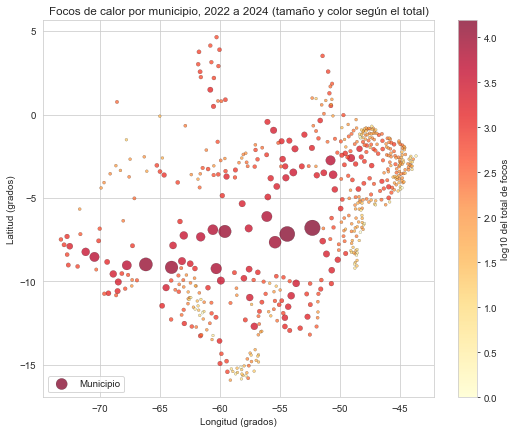

In [31]:
fig, ax = plt.subplots(figsize=(9, 7))
puntos = ax.scatter(por_municipio["lon"], por_municipio["lat"], s=8 + por_municipio["num_incendios"] / por_municipio["num_incendios"].max() * 250,
                    c=np.log10(por_municipio["num_incendios"].clip(lower=1)), cmap="YlOrRd", alpha=0.75, edgecolor="k", linewidth=0.2, label="Municipio")
ax.set_title("Focos de calor por municipio, 2022 a 2024 (tamaño y color según el total)")
ax.set_xlabel("Longitud (grados)")
ax.set_ylabel("Latitud (grados)")
plt.colorbar(puntos, label="log10 del total de focos")
ax.legend(loc="lower left")
plt.show()


**Figura 14.** Mapa de dispersión con un punto por municipio (centroide), con tamaño y color según el total de focos. Subconjunto `ENT`, 2022 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- Pará concentra **39.3 %** de los focos de 2022 a 2024, Amazonas **18.7 %** y Mato Grosso **16.7 %**.
- Los municipios con más focos son `SAO FELIX DO XINGU` (**15,504**, 4.4 %), `ALTAMIRA` (**14,591**, 4.1 %) y `LABREA` (**11,018**, 3.1 %).
- Los 10 municipios principales concentran **27.0 %** de los focos y los 50 principales **57.3 %** (de **543** municipios). Solo **1** municipio no tiene ningún foco en 2022 a 2024.
- Gráficos de apoyo: Figura 13 y Figura 14.

**Por qué importa**
- La concentración es alta pero no extrema: hay una cola de muchos municipios con pocos focos, lo que explica la masa de ceros.
- Pocos municipios pesan mucho en las métricas de error absoluto.

**Qué implica para Data Preparation y el modelado**
- `uf`, `lat` y `lon` son candidatas como predictoras de ubicación. Conviene reportar el error también por estado, no solo el agregado.


### Problema por estado: homogeneidad del error y desplazamiento

Se comprueba si el problema es parecido en todos los estados o si alguno domina el error. Con **2022 a 2024** (`ENT_OBJ` para lo que usa el target) se calcula, por estado: focos totales, porcentaje de semanas-municipio con focos, media y porcentaje de ceros de `focos_t1`, MAE de la persistencia (`focos_t1 = focos_t`), la correlación de `num_incendios` con `focos_t1` y el aporte de cada estado al error absoluto total. Las columnas de **desplazamiento** (porcentaje de semanas con focos y media de focos por año) son **solo descriptivas**: usan cada año completo y 2026 hasta su última semana (la 42).


In [32]:
obj_estado = df.loc[ENT_OBJ & df["focos_t1"].notna(), ["uf", "num_incendios", "focos_t1"]].copy()
obj_estado["error_abs"] = (obj_estado["focos_t1"] - obj_estado["num_incendios"]).abs()
focos_ent = df[ENT].groupby("uf")["num_incendios"]

por_estado = pd.DataFrame({
    "municipios": df.groupby("uf")["municipio_norm"].nunique(),
    "focos_totales": focos_ent.sum(),
    "pct_semanas_con_focos": focos_ent.apply(lambda s: (s > 0).mean() * 100),
    "media_focos_t1": obj_estado.groupby("uf")["focos_t1"].mean(),
    "pct_ceros_focos_t1": obj_estado.groupby("uf")["focos_t1"].apply(lambda s: (s == 0).mean() * 100),
    "mae_persistencia": obj_estado.groupby("uf")["error_abs"].mean(),
    "corr_focos_t_t1": obj_estado.groupby("uf")[["num_incendios", "focos_t1"]].apply(lambda g: g["num_incendios"].corr(g["focos_t1"])),
}).sort_values("focos_totales", ascending=False)
por_estado["aporte_error_total_pct"] = obj_estado.groupby("uf")["error_abs"].sum() / obj_estado["error_abs"].sum() * 100
por_estado["pct_municipios"] = por_estado["municipios"] / por_estado["municipios"].sum() * 100

print("Por estado, 2022 a 2024 (persistencia sobre focos_t1):")
mostrar(por_estado, 2)


Por estado, 2022 a 2024 (persistencia sobre focos_t1):
    municipios  focos_totales  pct_semanas_con_focos  media_focos_t1  pct_ceros_focos_t1  mae_persistencia  corr_focos_t_t1  aporte_error_total_pct  pct_municipios
uf                                                                                                                                                                 
PA         144         139344                  37.53            6.26               62.41              4.69             0.78                   37.74           26.52
AM          62          66315                  34.95            6.98               64.41              5.06             0.79                   17.54           11.42
MT          90          59103                  40.09            4.28               59.31              3.38             0.78                   17.02           16.57
RO          52          30560                  28.49            3.84               71.00              3.06             0.79  

In [33]:
orden_estados = por_estado.index
pct_anio = df.groupby(["uf", "anio"])["num_incendios"].apply(lambda s: (s > 0).mean() * 100).unstack("anio").loc[orden_estados]
media_anio = df.groupby(["uf", "anio"])["num_incendios"].mean().unstack("anio").loc[orden_estados]
print("Desplazamiento por estado: porcentaje de semanas-municipio con focos, por año (2026 hasta la semana 42):")
mostrar(pct_anio, 2)
print("\nDesplazamiento por estado: media de focos por semana-municipio, por año:")
mostrar(media_anio, 2)


Desplazamiento por estado: porcentaje de semanas-municipio con focos, por año (2026 hasta la semana 42):
anio  2022  2023  2024  2025  2026
uf                                
PA   33.84 38.69 40.02 32.09 27.98
AM   31.70 37.03 36.09 21.15 24.31
MT   38.44 39.98 41.82 27.03 24.58
RO   29.44 28.77 27.29 15.35 11.77
AC   38.64 34.09 37.48 24.83 27.60
MA   19.95 23.47 23.49 21.89 14.09
RR   38.08 54.74 54.47 43.33 56.83
AP   18.99 29.21 21.34 21.88 18.45
TO    8.79  9.78 11.75 10.27  7.96

Desplazamiento por estado: media de focos por semana-municipio, por año:
anio  2022  2023  2024  2025  2026
uf                                
PA    5.53  5.57  7.36  2.49  3.58
AM    6.58  6.08  7.76  1.41  3.22
MT    4.50  2.73  5.30  1.41  1.50
RO    4.61  2.74  3.88  0.70  0.60
AC   10.35  5.74  7.43  1.91  2.31
MA    0.80  0.90  1.09  1.21  0.44
RR    1.56  3.41  6.78  2.00  3.60
AP    1.19  3.07  2.38  1.15  1.59
TO    0.20  0.20  0.40  0.25  0.20


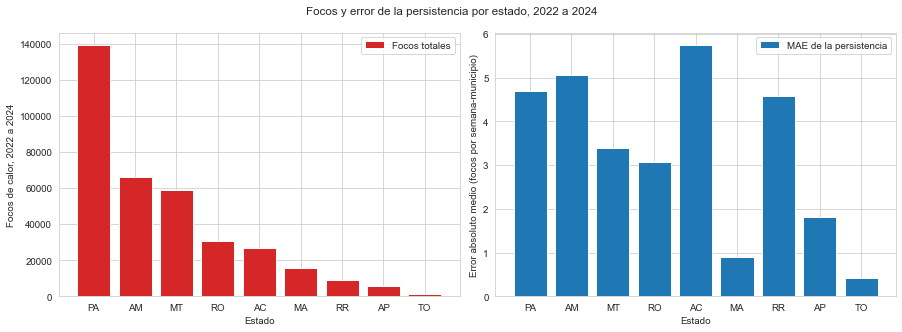

In [34]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
ejes[0].bar(por_estado.index, por_estado["focos_totales"], color="tab:red", label="Focos totales")
ejes[0].set_xlabel("Estado")
ejes[0].set_ylabel("Focos de calor, 2022 a 2024")
ejes[0].legend()
ejes[1].bar(por_estado.index, por_estado["mae_persistencia"], color="tab:blue", label="MAE de la persistencia")
ejes[1].set_xlabel("Estado")
ejes[1].set_ylabel("Error absoluto medio (focos por semana-municipio)")
ejes[1].legend()
fig.suptitle("Focos y error de la persistencia por estado, 2022 a 2024")
plt.tight_layout()
plt.show()


**Figura 15.** A la izquierda, focos totales por estado; a la derecha, MAE de la persistencia (`focos_t1 = focos_t`) por estado. Subconjunto `ENT_OBJ`, 2022 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- Pará tiene **139,344** focos y aporta **37.74 %** del error absoluto de la persistencia (con **26.52 %** de los municipios). Amazonas aporta **17.54 %** y Mato Grosso **17.02 %**.
- El MAE de la persistencia varía mucho: **5.75** (`AC`), **5.06** (`AM`) y **4.69** (`PA`), frente a **0.91** (`MA`) y **0.42** (`TO`).
- La correlación de `focos_t` con `focos_t1` es parecida en `PA`, `AM`, `MT`, `RO` y `AC` (**0.78** a **0.79**), pero baja en `RR` y `TO` (**0.24**), `MA` (**0.62**) y `AP` (**0.68**). El porcentaje de ceros de `focos_t1` va de **51.50 %** (`RR`) a **89.67 %** (`TO`).
- El desplazamiento no es parejo. El porcentaje de semanas con focos cae en `PA` de **40.02 %** (2024) a **32.09 %** (2025) y **27.98 %** (2026), y en `RO` de **27.29 %** a **15.35 %** y **11.77 %**. En `RR` va de **54.47 %** a **43.33 %** y sube a **56.83 %** en 2026.
- Gráficos de apoyo: Figura 15.

**Por qué importa**
- El problema **no es homogéneo**: el error se concentra en los estados con más focos, y la persistencia funciona bien en los cinco principales pero casi no sirve en `RR` y `TO`.
- La media de focos por semana-municipio también cambia distinto: en `AM` pasa de **7.76** (2024) a **1.41** (2025) y **3.22** (2026), mientras que en `MA` va de **1.09** a **1.21** y **0.44**.

**Qué implica para Data Preparation y el modelado**
- Se incluye `uf` (o variables de ubicación) y se reportan las métricas por estado, no solo el agregado.
- **Limitación:** el desplazamiento difiere por estado (`RR` sube en 2026 mientras `PA`, `AM`, `MT` y `RO` bajan), así que un solo ajuste global no lo corrige.


## 9. Correlaciones con los targets

Se calculan Pearson y Spearman de cada predictora (focos, `frp_total`, NASA POWER, SISAM, DETER) contra `focos_t1` y `focos_4s`, **solo con `ENT_OBJ`**. Spearman es la medida más fiable aquí porque los focos tienen cola larga y muchos ceros. Luego se separa por temporada, y se calcula la **correlación parcial** de cada predictora con `focos_t1` controlando por `focos_t`: ambas variables se corrigen con una recta sobre `log1p(focos_t)` y se correlacionan los residuos (versión Pearson, versión Pearson con `log1p(focos_t1)` y versión Spearman con rangos). Esta es la prueba clave para saber si SISAM y NASA aportan algo **más allá de la persistencia**. Al final, la correlación cruzada de NASA con rezagos de 1 a 4 semanas.


Correlación de cada predictora con los targets (83,079 filas, 2022 a 2024):
                                 focos_t1          focos_4s         
                                  pearson spearman  pearson spearman
predictora                                                          
num_incendios                       0.780    0.629    0.655    0.657
frp_total                           0.732    0.627    0.624    0.655
T2M                                 0.117    0.311    0.112    0.348
RH2M                               -0.150   -0.354   -0.156   -0.409
WS2M                               -0.071   -0.187   -0.081   -0.202
T2M_MAX                             0.136    0.339    0.135    0.378
precip_nasa_sem                    -0.101   -0.329   -0.119   -0.424
dias_sin_lluvia_nasa                0.054    0.277    0.067    0.350
precip_acum_30d                    -0.124   -0.383   -0.145   -0.487
precip_acum_120d                   -0.130   -0.373   -0.134   -0.420
pm10_reanalise             

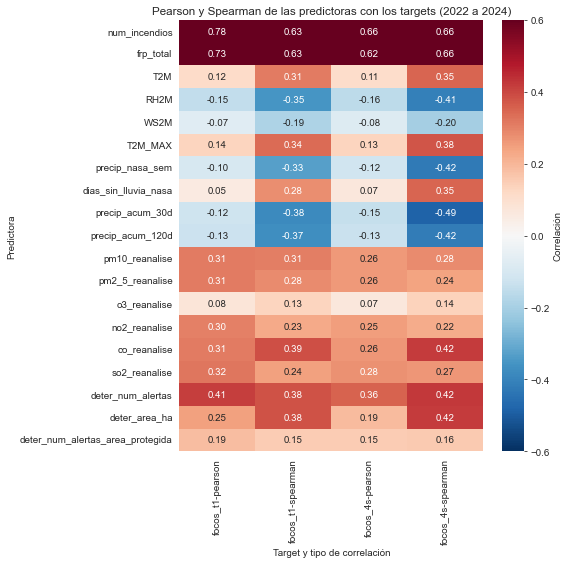

In [35]:
COLS_FOCOS = ["num_incendios", "frp_total"]
COLS_NASA = ["T2M", "RH2M", "WS2M", "T2M_MAX", "precip_nasa_sem", "dias_sin_lluvia_nasa", "precip_acum_30d", "precip_acum_120d"]
COLS_SISAM = ["pm10_reanalise", "pm2_5_reanalise", "o3_reanalise", "no2_reanalise", "co_reanalise", "so2_reanalise"]
COLS_DETER = ["deter_num_alertas", "deter_area_ha", "deter_num_alertas_area_protegida"]
PREDICTORAS = COLS_FOCOS + COLS_NASA + COLS_SISAM + COLS_DETER
OBJETIVOS = ["focos_t1", "focos_4s"]

base_corr = df.loc[ENT_OBJ & df["focos_t1"].notna() & df["focos_4s"].notna()]


def tabla_correlaciones(datos, predictoras, objetivo):
    filas = []
    for x in predictoras:
        filas.append({"predictora": x,
                      "pearson": datos[x].corr(datos[objetivo]),
                      "spearman": datos[x].corr(datos[objetivo], method="spearman")})
    return pd.DataFrame(filas).set_index("predictora")


corr_t1 = tabla_correlaciones(base_corr, PREDICTORAS, "focos_t1")
corr_4s = tabla_correlaciones(base_corr, PREDICTORAS, "focos_4s")
resumen_corr = pd.concat({"focos_t1": corr_t1, "focos_4s": corr_4s}, axis=1)
print(f"Correlación de cada predictora con los targets ({len(base_corr):,} filas, 2022 a 2024):")
mostrar(resumen_corr, 3)

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(resumen_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, ax=ax, cbar_kws={"label": "Correlación"})
ax.set_title("Pearson y Spearman de las predictoras con los targets (2022 a 2024)")
ax.set_xlabel("Target y tipo de correlación")
ax.set_ylabel("Predictora")
plt.show()


**Figura 16.** Mapa de calor con la correlación de Pearson y de Spearman de cada predictora con `focos_t1` y `focos_4s`. Subconjunto `ENT_OBJ`.


Correlación con focos_t1 por temporada (2022 a 2024):
Filas de temporada seca: 35,838 | húmeda: 47,241
                                    seca           humeda         
                                 pearson spearman pearson spearman
predictora                                                        
num_incendios                      0.780    0.643   0.464    0.494
frp_total                          0.735    0.633   0.286    0.494
T2M                                0.050    0.184   0.057    0.007
RH2M                              -0.082   -0.113  -0.177   -0.166
WS2M                              -0.109   -0.269  -0.061   -0.165
T2M_MAX                            0.068    0.161   0.120    0.092
precip_nasa_sem                   -0.058   -0.048  -0.135   -0.237
dias_sin_lluvia_nasa               0.001    0.033   0.177    0.216
precip_acum_30d                   -0.079   -0.074  -0.169   -0.265
precip_acum_120d                  -0.080   -0.139  -0.133   -0.194
pm10_reanalise            

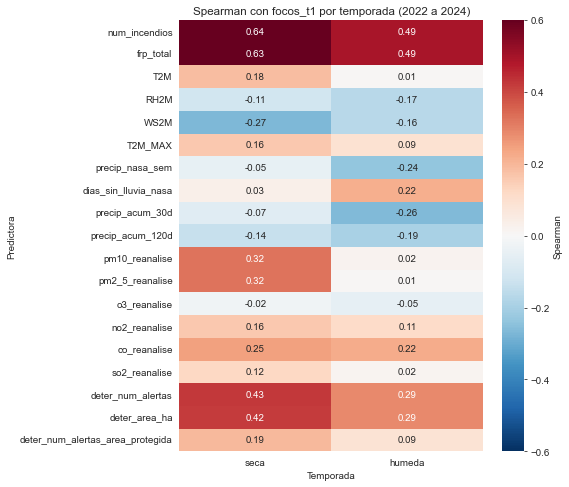

In [36]:
por_temp = {}
for temporada in ["seca", "humeda"]:
    por_temp[temporada] = tabla_correlaciones(base_corr[base_corr["temporada"] == temporada], PREDICTORAS, "focos_t1")
por_temp = pd.concat(por_temp, axis=1)
print("Correlación con focos_t1 por temporada (2022 a 2024):")
print("Filas de temporada seca:", f"{(base_corr['temporada'] == 'seca').sum():,}", "| húmeda:", f"{(base_corr['temporada'] == 'humeda').sum():,}")
mostrar(por_temp, 3)

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(por_temp.xs("spearman", axis=1, level=1), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, ax=ax,
            cbar_kws={"label": "Spearman"})
ax.set_title("Spearman con focos_t1 por temporada (2022 a 2024)")
ax.set_xlabel("Temporada")
ax.set_ylabel("Predictora")
plt.show()


**Figura 17.** Correlación de Spearman de cada predictora con `focos_t1`, separada por temporada seca (julio a noviembre) y húmeda. Subconjunto `ENT_OBJ`.


In [37]:
def residuos_lineales(y, z):
    # residuo de la regresion lineal simple de y sobre z
    pendiente, intercepto = np.polyfit(z, y, 1)
    return y - (intercepto + pendiente * z)


def correlacion_parcial(datos, x, objetivo="focos_t1", control="num_incendios"):
    d = datos[[x, objetivo, control]].dropna()
    z = np.log1p(d[control])
    pearson = np.corrcoef(residuos_lineales(d[x], z), residuos_lineales(d[objetivo], z))[0, 1]
    rangos = d.rank()
    z_r = np.log1p(d[control]).rank()
    spearman = np.corrcoef(residuos_lineales(rangos[x], z_r), residuos_lineales(rangos[objetivo], z_r))[0, 1]
    pearson_log = np.corrcoef(residuos_lineales(d[x], z), residuos_lineales(np.log1p(d[objetivo]), z))[0, 1]
    return pearson, spearman, pearson_log


filas = []
for x in [c for c in PREDICTORAS if c != "num_incendios"]:
    parcial_p, parcial_s, parcial_log = correlacion_parcial(base_corr, x)
    filas.append({"predictora": x, "pearson_simple": corr_t1.loc[x, "pearson"], "pearson_parcial": parcial_p,
                  "pearson_parcial_log1p": parcial_log,
                  "spearman_simple": corr_t1.loc[x, "spearman"], "spearman_parcial": parcial_s})
tabla_parcial = pd.DataFrame(filas).set_index("predictora")
print("Correlación simple y parcial con focos_t1 (controlando por log1p(focos_t)), 2022 a 2024:")
mostrar(tabla_parcial, 3)
print("\nReferencia, correlación de num_incendios (focos_t) con focos_t1:",
      f"pearson {corr_t1.loc['num_incendios', 'pearson']:.3f} | spearman {corr_t1.loc['num_incendios', 'spearman']:.3f}")


Correlación simple y parcial con focos_t1 (controlando por log1p(focos_t)), 2022 a 2024:
                                  pearson_simple  pearson_parcial  pearson_parcial_log1p  spearman_simple  spearman_parcial
predictora                                                                                                                 
frp_total                                  0.732            0.670                  0.082            0.627             0.001
T2M                                        0.117           -0.055                  0.076            0.311             0.129
RH2M                                      -0.150            0.027                 -0.103           -0.354            -0.158
WS2M                                      -0.071           -0.006                 -0.058           -0.187            -0.091
T2M_MAX                                    0.136           -0.049                  0.097            0.339             0.146
precip_nasa_sem                           -

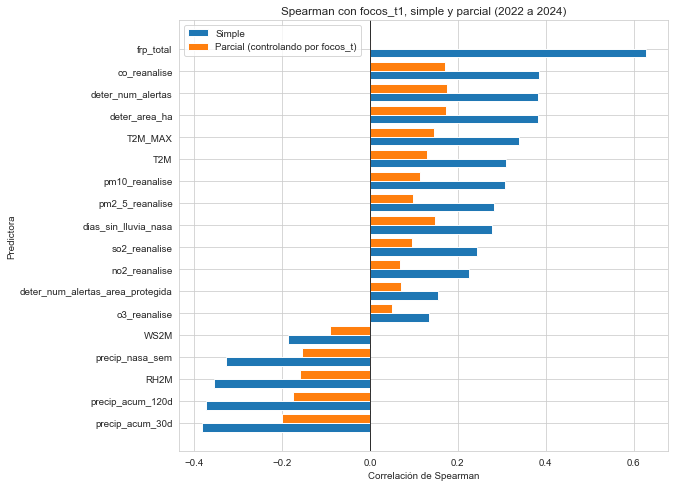

In [38]:
orden = tabla_parcial.sort_values("spearman_simple").index
posicion = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(posicion - 0.2, tabla_parcial.loc[orden, "spearman_simple"], height=0.4, label="Simple", color="tab:blue")
ax.barh(posicion + 0.2, tabla_parcial.loc[orden, "spearman_parcial"], height=0.4, label="Parcial (controlando por focos_t)", color="tab:orange")
ax.set_yticks(posicion)
ax.set_yticklabels(orden)
ax.axvline(0, color="k", linewidth=0.8)
ax.set_title("Spearman con focos_t1, simple y parcial (2022 a 2024)")
ax.set_xlabel("Correlación de Spearman")
ax.set_ylabel("Predictora")
ax.legend()
plt.show()


**Figura 18.** Correlación de Spearman con `focos_t1`, simple y controlando por `log1p(focos_t)`, para cada predictora. Subconjunto `ENT_OBJ`.


Spearman entre la variable NASA rezagada k semanas y num_incendios de la semana t (2022 a 2024):
                      rezago_0  rezago_1  rezago_2  rezago_3  rezago_4
T2M                      0.343     0.310     0.295     0.284     0.260
RH2M                    -0.381    -0.353    -0.338    -0.327    -0.308
WS2M                    -0.185    -0.185    -0.181    -0.177    -0.172
precip_nasa_sem         -0.343    -0.329    -0.330    -0.349    -0.363
dias_sin_lluvia_nasa     0.264     0.278     0.274     0.285     0.308
precip_acum_30d         -0.380    -0.384    -0.389    -0.397    -0.396


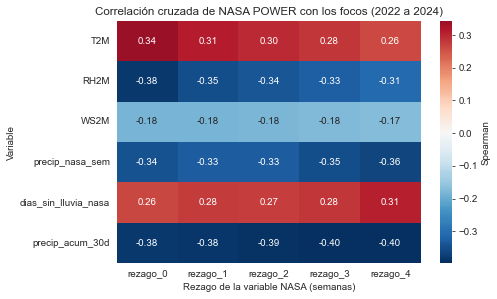

In [39]:
VARS_CRUZADA = ["T2M", "RH2M", "WS2M", "precip_nasa_sem", "dias_sin_lluvia_nasa", "precip_acum_30d"]
filas = {}
for variable in VARS_CRUZADA:
    por_rezago = {}
    for k in range(0, 5):
        x_rezagado = df.groupby(CLAVE)[variable].shift(k) if k else df[variable]
        d = pd.DataFrame({"x": x_rezagado[ENT], "y": df.loc[ENT, "num_incendios"]}).dropna()
        por_rezago[f"rezago_{k}"] = d["x"].corr(d["y"], method="spearman")
    filas[variable] = por_rezago
cruzada = pd.DataFrame(filas).T
print("Spearman entre la variable NASA rezagada k semanas y num_incendios de la semana t (2022 a 2024):")
mostrar(cruzada, 3)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(cruzada, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "Spearman"})
ax.set_title("Correlación cruzada de NASA POWER con los focos (2022 a 2024)")
ax.set_xlabel("Rezago de la variable NASA (semanas)")
ax.set_ylabel("Variable")
plt.show()


**Figura 19.** Correlación de Spearman entre cada variable de NASA POWER rezagada de 0 a 4 semanas y los focos de la semana. Subconjunto `ENT`.


### Hallazgos de esta etapa

**Qué se observa**
- Con `focos_t1`, la mayor correlación de Spearman es la de `num_incendios` (**0.629**) y `frp_total` (**0.627**). Entre las ambientales destacan `precip_acum_30d` (**-0.383**), `precip_acum_120d` (**-0.373**), `RH2M` (**-0.354**) y `T2M_MAX` (**0.339**). En SISAM, `co_reanalise` (**0.386**) y `pm10_reanalise` (**0.308**).
- Al controlar por `focos_t`, el Spearman parcial cae: `frp_total` **0.001**, `precip_acum_30d` **-0.201**, `precip_acum_120d` **-0.175**, `co_reanalise` **0.171**, `T2M_MAX` **0.146**, `pm10_reanalise` **0.114** y `no2_reanalise` **0.069**.
- El Pearson parcial en escala original da otra imagen: `frp_total` **0.670**, `deter_num_alertas` **0.314**, los contaminantes entre **0.147** y **0.183** (salvo `o3_reanalise`) y el clima entre **-0.055** y **0.043**. Con `log1p(focos_t1)` esas cifras bajan: `frp_total` **0.082**, los contaminantes entre **0.028** y **0.084**, y el clima entre **-0.139** (`precip_acum_30d`) y **0.097** (`T2M_MAX`).
- Por temporada, en la seca `pm10_reanalise` tiene Spearman **0.325** y en la húmeda **0.023**. `precip_acum_30d` pesa más en la húmeda (**-0.265**) que en la seca (**-0.074**).
- Con rezagos de 1 a 4 semanas, `precip_acum_30d` mantiene su correlación (de **-0.380** a **-0.396**) y `dias_sin_lluvia_nasa` sube (de **0.264** a **0.308**). `T2M` baja de **0.343** a **0.260**.
- Gráficos de apoyo: Figura 16, Figura 17, Figura 18 y Figura 19.

**Por qué importa**
- El **Pearson en escala original está dominado por los extremos** (pocas semanas con cientos de focos). Por eso `frp_total` parece conservar **0.670** y el clima parece cercano a cero. **La lectura principal es el Spearman y el Pearson con `log1p`**, que coinciden en signo y en orden.
- Con esas dos medidas, el clima **no es nulo**: tiene una señal pequeña pero consistente. Por ejemplo, `precip_acum_30d` da **+0.040** en Pearson parcial con escala original, pero **-0.139** con `log1p` y **-0.201** en Spearman parcial. Es la ambiental más fuerte.
- La persistencia domina: buena parte de la correlación de las predictoras con `focos_t1` desaparece al controlar por los focos actuales, con los que comparten la estacionalidad.
- SISAM mide el humo de los mismos focos, así que su aporte parcial puede ser parte del propio fuego. Es una lectura, no una prueba. DETER tiene un Spearman parcial de **0.175**, pero es solo contexto de KPI y no se usa como predictora.

**Qué implica para Data Preparation y el modelado**
- Se construyen rezagos de NASA de 1 a 4 semanas, sobre todo acumulados de lluvia y días sin lluvia.
- SISAM entra **solo a la ablación** (modelo con y sin SISAM), porque su aporte más allá de la persistencia es pequeño (Spearman parcial entre **0.051** y **0.171**; Pearson parcial con `log1p` entre **0.028** y **0.084**).


## 10. Colinealidad entre predictoras

Matriz de correlación de Pearson entre las predictoras (**solo 2022 a 2024, `ENT`**) y lista de los pares con |r| mayor que 0.9. El factor de inflación de la varianza (VIF) formal se calcula en Data Preparation.


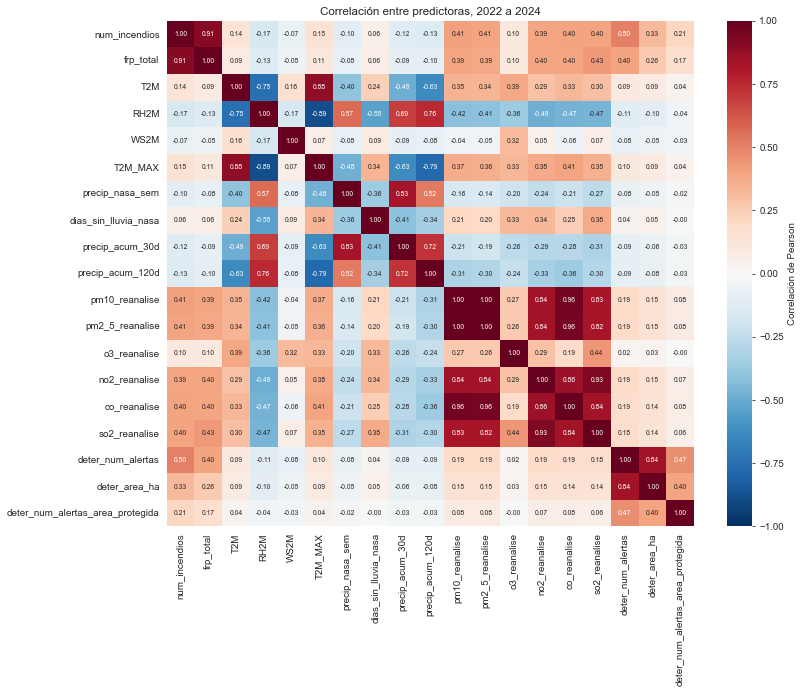

In [40]:
matriz_corr = df.loc[ENT, PREDICTORAS].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Correlación entre predictoras, 2022 a 2024")
plt.tight_layout()
plt.show()


**Figura 20.** Matriz de correlación de Pearson entre las 19 predictoras. Subconjunto `ENT`, 2022 a 2024.


In [41]:
superior = matriz_corr.where(np.triu(np.ones(matriz_corr.shape, dtype=bool), k=1))
pares_altos = superior.stack().rename("r").reset_index()
pares_altos.columns = ["variable_a", "variable_b", "r"]
pares_altos = pares_altos[pares_altos["r"].abs() > 0.9].sort_values("r", key=abs, ascending=False)
print(f"Pares con |r| > 0.9 ({len(pares_altos)}):")
mostrar(pares_altos.reset_index(drop=True), 3)

print("\nOtros pares con |r| entre 0.7 y 0.9:")
medios = superior.stack().rename("r").reset_index()
medios.columns = ["variable_a", "variable_b", "r"]
mostrar(medios[medios["r"].abs().between(0.7, 0.9)].sort_values("r", key=abs, ascending=False).reset_index(drop=True), 3)


Pares con |r| > 0.9 (5):
        variable_a       variable_b     r
0   pm10_reanalise  pm2_5_reanalise 0.999
1   pm10_reanalise     co_reanalise 0.962
2  pm2_5_reanalise     co_reanalise 0.959
3    no2_reanalise    so2_reanalise 0.933
4    num_incendios        frp_total 0.914

Otros pares con |r| entre 0.7 y 0.9:
           variable_a        variable_b      r
0                RH2M           T2M_MAX -0.890
1                 T2M           T2M_MAX  0.884
2       no2_reanalise      co_reanalise  0.857
3      pm10_reanalise     no2_reanalise  0.843
4        co_reanalise     so2_reanalise  0.838
5     pm2_5_reanalise     no2_reanalise  0.838
6   deter_num_alertas     deter_area_ha  0.838
7     precip_nasa_sem   precip_acum_30d  0.831
8      pm10_reanalise     so2_reanalise  0.828
9     pm2_5_reanalise     so2_reanalise  0.821
10            T2M_MAX  precip_acum_120d -0.787
11               RH2M  precip_acum_120d  0.757
12                T2M              RH2M -0.754
13    precip_acum_30d  prec

### Hallazgos de esta etapa

**Qué se observa**
- Hay **5** pares con |r| mayor a 0.9: `pm10_reanalise` con `pm2_5_reanalise` (**0.999**), `pm10_reanalise` con `co_reanalise` (**0.962**), `pm2_5_reanalise` con `co_reanalise` (**0.959**), `no2_reanalise` con `so2_reanalise` (**0.933**) y `num_incendios` con `frp_total` (**0.914**).
- Quedan justo por debajo: `RH2M` con `T2M_MAX` (**-0.890**), `T2M` con `T2M_MAX` (**0.884**) y `precip_nasa_sem` con `precip_acum_30d` (**0.831**). `precip_acum_30d` con `precip_acum_120d` es **0.725**.
- Gráficos de apoyo: Figura 20.

**Por qué importa**
- Los contaminantes de SISAM son casi la misma señal repetida. `pm10` y `pm2_5` son prácticamente idénticos.
- `T2M` con `T2M_MAX` y los dos acumulados de lluvia **no superan 0.9**, aunque se esperaba: no hay evidencia para retirarlos solo por colinealidad.

**Qué implica para Data Preparation y el modelado**
- Se retira `pm2_5_reanalise` (r = **0.999** con `pm10_reanalise`) y se elige un solo representante entre `pm10_reanalise` y `co_reanalise`, y otro entre `no2_reanalise` y `so2_reanalise`. `frp_total` es candidata a retirarse por su relación con `num_incendios`.
- El VIF formal confirma la decisión en Data Preparation.


## 11. Covarianza y dispersión

**Subconjunto:** `ENT_OBJ` (2022 a 2024 con margen de 4 semanas). Esta sección tiene tres partes:
- La **matriz de covarianza** de todas las predictoras numéricas (focos, NASA POWER y SISAM) más `focos_t1` y `focos_4s`, primero en escala original y luego con las variables estandarizadas.
- Los **gráficos de dispersión** de cada predictora contra `focos_t1` y `focos_4s` (muestra de 5,000 filas y media por intervalos), con la tabla de correlaciones de cada par.
- Para el **Frente 2**, donde el target es categórico y la dispersión no aplica, **boxplots** de las predictoras principales por `clase_t1`. Cierra con un pairplot de una muestra de 3,000 filas.


### Covarianza detallada

La covarianza entre dos variables mide si se mueven juntas (signo positivo) o en sentido contrario (signo negativo). **Depende de la escala**: una variable con valores grandes (como `frp_total`) tiene covarianzas enormes aunque su relación sea débil, y por eso no se puede comparar entre variables de distinta escala. La diagonal es la **varianza** de cada variable. Si las variables se **estandarizan** (media 0 y desviación 1), la covarianza coincide con la correlación y pasa a ser comparable entre variables. Por eso se muestran ambas versiones y la correlación complementa a la covarianza.


In [42]:
PRED_DISP = COLS_FOCOS + COLS_NASA + COLS_SISAM
datos_cov = df.loc[ENT_OBJ & df["focos_t1"].notna() & df["focos_4s"].notna(), PRED_DISP + OBJETIVOS]
covarianza = datos_cov.cov()
print(f"Matriz de covarianza en escala original ({len(datos_cov):,} filas, 2022 a 2024):")
print(covarianza.to_string(float_format=lambda v: f"{v:,.1f}"))


Matriz de covarianza en escala original (83,079 filas, 2022 a 2024):
                      num_incendios   frp_total    T2M     RH2M  WS2M  T2M_MAX  precip_nasa_sem  dias_sin_lluvia_nasa  precip_acum_30d  precip_acum_120d  pm10_reanalise  pm2_5_reanalise  o3_reanalise  no2_reanalise  co_reanalise  so2_reanalise  focos_t1  focos_4s
num_incendios                 759.3    61,531.6    8.7    -76.3  -1.4     16.0            -95.5                  24.2           -408.3          -1,484.9           385.9            278.4          40.9           20.3           2.2            7.5     592.5   1,738.9
frp_total                  61,531.6 5,972,475.1  505.9 -5,229.5 -98.2    997.2         -6,332.0               2,447.5        -27,258.1         -96,303.9        32,860.6         23,744.4       3,399.7        1,811.0         191.3          711.6  49,289.8 146,927.2
T2M                             8.7       505.9    5.4    -29.3   0.3      7.9            -30.8                   8.9           -137.3     

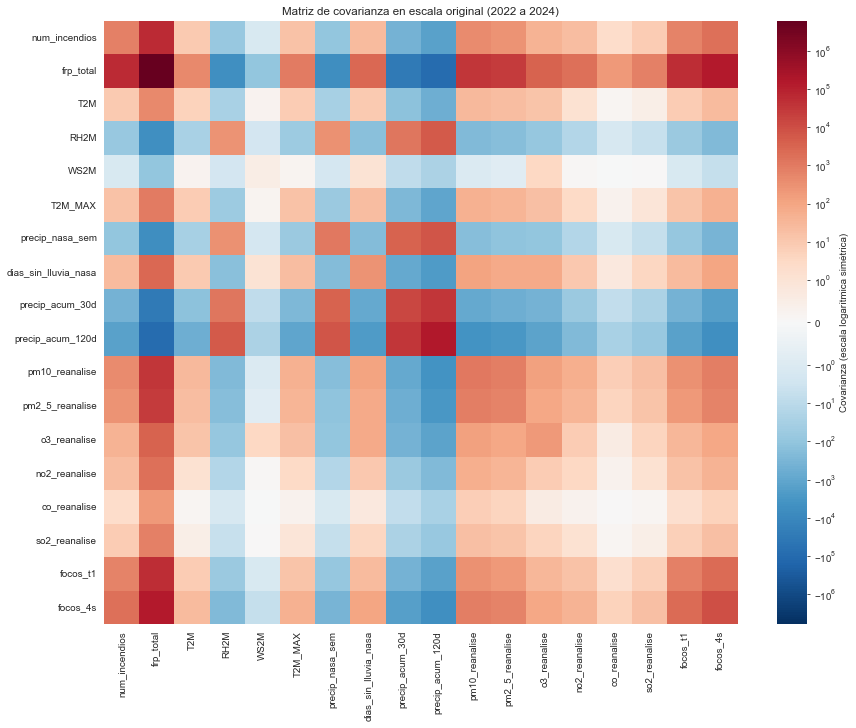

In [43]:
limite = covarianza.abs().to_numpy().max()
fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(covarianza, cmap="RdBu_r", norm=SymLogNorm(linthresh=1, vmin=-limite, vmax=limite), ax=ax,
            cbar_kws={"label": "Covarianza (escala logarítmica simétrica)"})
ax.set_title("Matriz de covarianza en escala original (2022 a 2024)")
plt.tight_layout()
plt.show()


**Figura 21.** Matriz de covarianza de las 16 predictoras y los dos targets en escala original, con color en escala logarítmica simétrica porque las magnitudes son muy distintas. Subconjunto `ENT_OBJ`.


Comprobado: la covarianza de las variables estandarizadas es igual a la matriz de correlación.


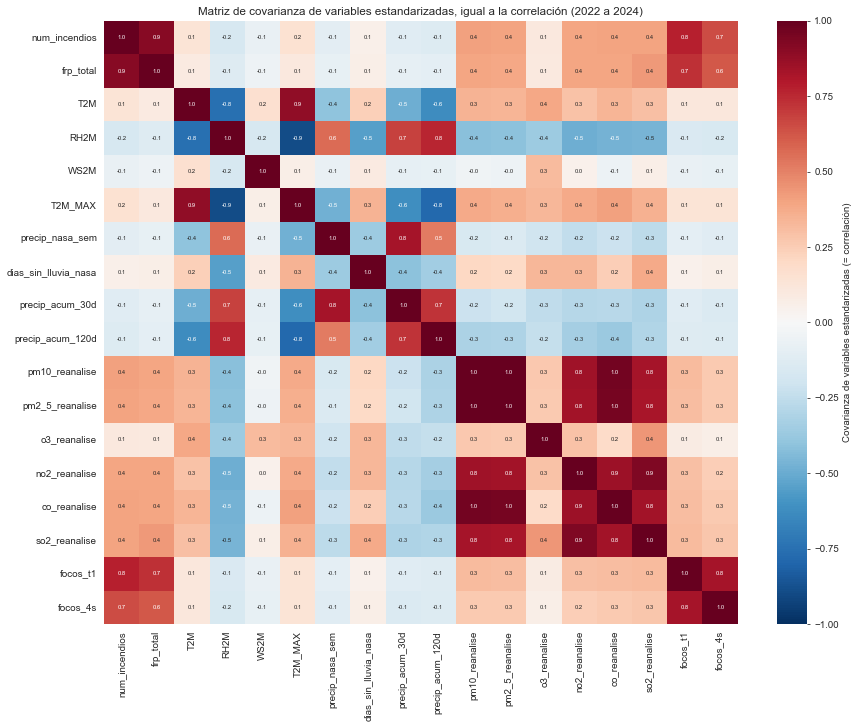

In [44]:
estandarizadas = (datos_cov - datos_cov.mean()) / datos_cov.std()
cov_estandarizada = estandarizadas.cov()
assert np.allclose(cov_estandarizada, datos_cov.corr()), "La covarianza estandarizada debe igualar la correlación"
print("Comprobado: la covarianza de las variables estandarizadas es igual a la matriz de correlación.")

fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(cov_estandarizada, annot=True, fmt=".1f", annot_kws={"size": 6}, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax,
            cbar_kws={"label": "Covarianza de variables estandarizadas (= correlación)"})
ax.set_title("Matriz de covarianza de variables estandarizadas, igual a la correlación (2022 a 2024)")
plt.tight_layout()
plt.show()


**Figura 22.** Matriz de covarianza de las mismas variables estandarizadas, que coincide con la correlación y es comparable entre variables. Subconjunto `ENT_OBJ`.


In [45]:
print("Varianza (diagonal) de cada variable, escala original:")
mostrar(pd.Series(np.diag(covarianza), index=covarianza.index).sort_values(ascending=False).to_frame("varianza"), 2)

for objetivo in OBJETIVOS:
    otras = covarianza[objetivo].drop(OBJETIVOS)
    estandar = cov_estandarizada[objetivo].drop(OBJETIVOS)
    print(f"\nCovarianzas más altas y más bajas con {objetivo} (escala original):")
    mostrar(pd.concat([otras.nlargest(5), otras.nsmallest(3)]).to_frame("covarianza"), 2)
    print(f"Covarianza estandarizada (= correlación) más alta y más baja con {objetivo}:")
    mostrar(pd.concat([estandar.nlargest(5), estandar.nsmallest(3)]).to_frame("cov_estandarizada"), 3)

superior = cov_estandarizada.where(np.triu(np.ones(cov_estandarizada.shape, dtype=bool), k=1))
opuestos = superior.stack().rename("cov_estandarizada").reset_index()
opuestos.columns = ["variable_a", "variable_b", "cov_estandarizada"]
print("\nPares que se mueven en sentido contrario (los 10 más negativos, estandarizados):")
mostrar(opuestos.nsmallest(10, "cov_estandarizada").reset_index(drop=True), 3)


Varianza (diagonal) de cada variable, escala original:
                         varianza
frp_total            5,972,475.08
precip_acum_120d       155,585.29
precip_acum_30d         14,508.58
focos_4s                 9,278.07
pm10_reanalise           1,177.76
precip_nasa_sem          1,096.65
focos_t1                   759.45
num_incendios              759.35
pm2_5_reanalise            619.46
RH2M                       277.17
dias_sin_lluvia_nasa       252.47
o3_reanalise               208.17
T2M_MAX                     14.80
T2M                          5.43
no2_reanalise                3.49
WS2M                         0.55
so2_reanalise                0.45
co_reanalise                 0.04

Covarianzas más altas y más bajas con focos_t1 (escala original):
                  covarianza
frp_total          49,289.81
num_incendios         592.50
pm10_reanalise        296.79
pm2_5_reanalise       213.74
o3_reanalise           31.28
precip_acum_120d   -1,414.30
precip_acum_30d      -411.86


### Hallazgos de esta etapa

**Qué se observa**
- La diagonal muestra escalas muy distintas: la varianza de `frp_total` es **5,972,475.08**, la de `precip_acum_120d` **155,585.29** y la de `co_reanalise` solo **0.04**.
- Con `focos_t1`, las covarianzas positivas más altas (escala original) son `frp_total` (**49,289.81**), `num_incendios` (**592.50**), `pm10_reanalise` (**296.79**) y `pm2_5_reanalise` (**213.74**). Las negativas son `precip_acum_120d` (**-1,414.30**), `precip_acum_30d` (**-411.86**) y `precip_nasa_sem` (**-92.29**). Con `focos_4s` el orden es el mismo (por ejemplo `precip_acum_120d` **-5,096.21**).
- Estandarizadas (iguales a la correlación), las mayores con `focos_t1` son `num_incendios` (**0.780**), `frp_total` (**0.732**) y `so2_reanalise` (**0.320**). Las negativas son `RH2M` (**-0.150**), `precip_acum_120d` (**-0.130**) y `precip_acum_30d` (**-0.124**).
- Los pares que se mueven en sentido contrario son `RH2M` con `T2M_MAX` (**-0.892**), `T2M_MAX` con `precip_acum_120d` (**-0.788**) y `T2M` con `RH2M` (**-0.754**).
- Gráficos de apoyo: Figura 21 y Figura 22.

**Por qué importa**
- La covarianza depende de la escala: `precip_acum_120d` tiene la mayor covarianza negativa con `focos_t1` (**-1,414.30**), pero su correlación es de solo **-0.130**. Por eso la covarianza no se puede comparar entre variables y se complementa con la correlación.
- Los mapas confirman que las variables de temperatura, humedad y lluvia acumulada se mueven en bloque, con signos opuestos entre calor y humedad.

**Qué implica para Data Preparation y el modelado**
- Las predictoras se estandarizan para los modelos sensibles a la escala, y no se usa la covarianza sin estandarizar para seleccionar variables.
- La redundancia entre `RH2M`, `T2M` y `T2M_MAX` refuerza el análisis de colinealidad de la sección 10.


### Dispersión de predictoras y boxplots por clase

Cada gráfico usa una **muestra de 5,000 filas** (`random_state` fijo) y dibuja además la **media de `log1p` del target por intervalos** (20 intervalos con el mismo número de filas de la población completa de `ENT_OBJ`), que muestra la tendencia aunque la nube de puntos esté saturada de ceros. Las variables de focos (`num_incendios` y `frp_total`) se muestran con `log1p` en el eje x. Las 16 predictoras se reparten en dos grupos de máximo 9 gráficos por figura. Luego, una tabla con la correlación (Pearson y Spearman) de cada par y los boxplots por clase del Frente 2.


In [46]:
filtro_disp = ENT_OBJ & df["focos_t1"].notna() & df["focos_4s"].notna()
base_disp = df.loc[filtro_disp]
muestra = base_disp.sample(5000, random_state=ALEATORIO)
GRUPO_1 = ["num_incendios", "frp_total", "T2M", "T2M_MAX", "RH2M", "WS2M", "precip_nasa_sem", "dias_sin_lluvia_nasa", "precip_acum_30d"]
GRUPO_2 = ["precip_acum_120d"] + COLS_SISAM


def graficar_dispersion(predictoras, objetivo, titulo):
    # cuadricula de hasta 3 x 3: puntos de la muestra y media del target (log1p) por intervalos
    fig, ejes = plt.subplots(3, 3, figsize=(16, 12))
    for eje, variable in zip(ejes.ravel(), predictoras):
        usar_log = variable in COLS_FOCOS
        x_m = np.log1p(muestra[variable]) if usar_log else muestra[variable]
        x_b = np.log1p(base_disp[variable]) if usar_log else base_disp[variable]
        eje.scatter(x_m, np.log1p(muestra[objetivo]), s=4, alpha=0.15, color="tab:blue", label="Semana-municipio (muestra de 5,000)")
        intervalos = pd.qcut(x_b, 20, duplicates="drop")
        medias = pd.DataFrame({"x": x_b, "y": np.log1p(base_disp[objetivo])}).groupby(intervalos, observed=True).mean()
        eje.plot(medias["x"], medias["y"], color="red", marker="o", markersize=4, label="Media por intervalo")
        eje.set_title(variable)
        eje.set_xlabel(f"log1p({variable})" if usar_log else variable)
        eje.set_ylabel(f"log1p({objetivo})")
        eje.legend(fontsize=7)
    for eje in ejes.ravel()[len(predictoras):]:
        eje.axis("off")
    fig.suptitle(titulo)
    fig.tight_layout()
    return fig


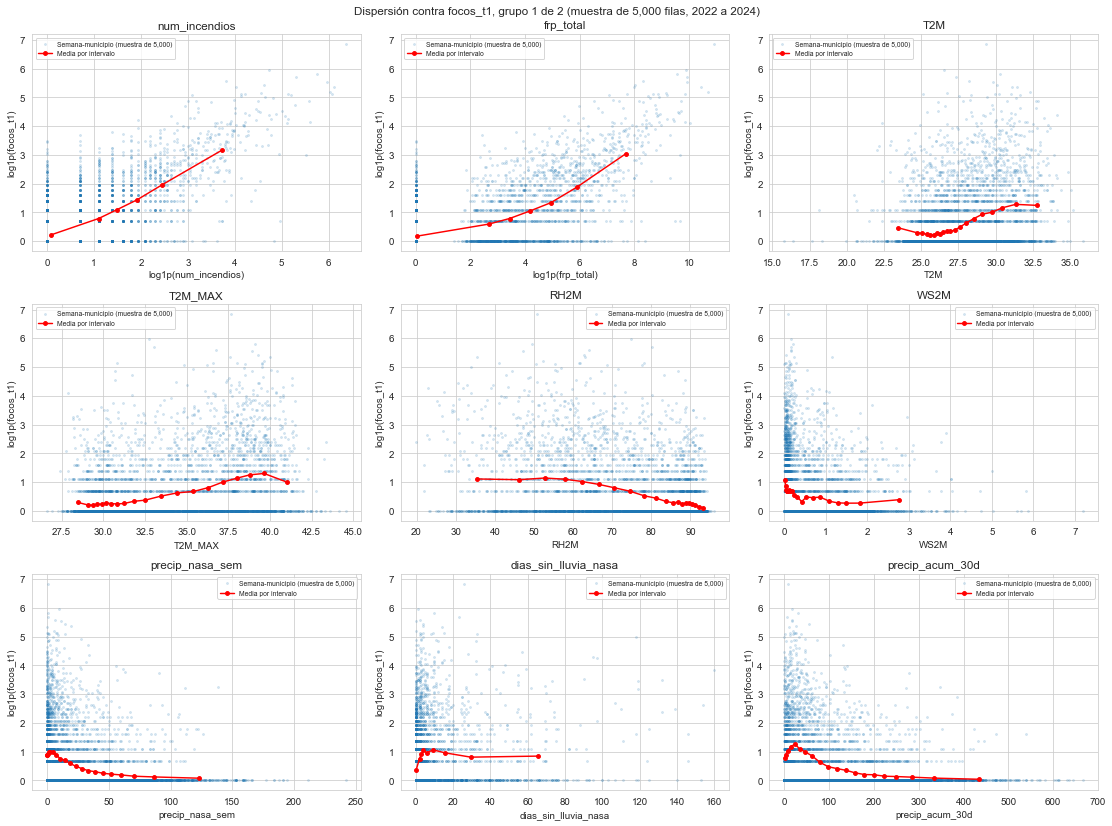

In [47]:
graficar_dispersion(GRUPO_1, "focos_t1", "Dispersión contra focos_t1, grupo 1 de 2 (muestra de 5,000 filas, 2022 a 2024)")
plt.show()


**Figura 23.** Dispersión de `num_incendios`, `frp_total` y siete variables de NASA POWER contra `focos_t1` (en `log1p`), con la media por intervalos. Muestra de 5,000 filas de `ENT_OBJ`.


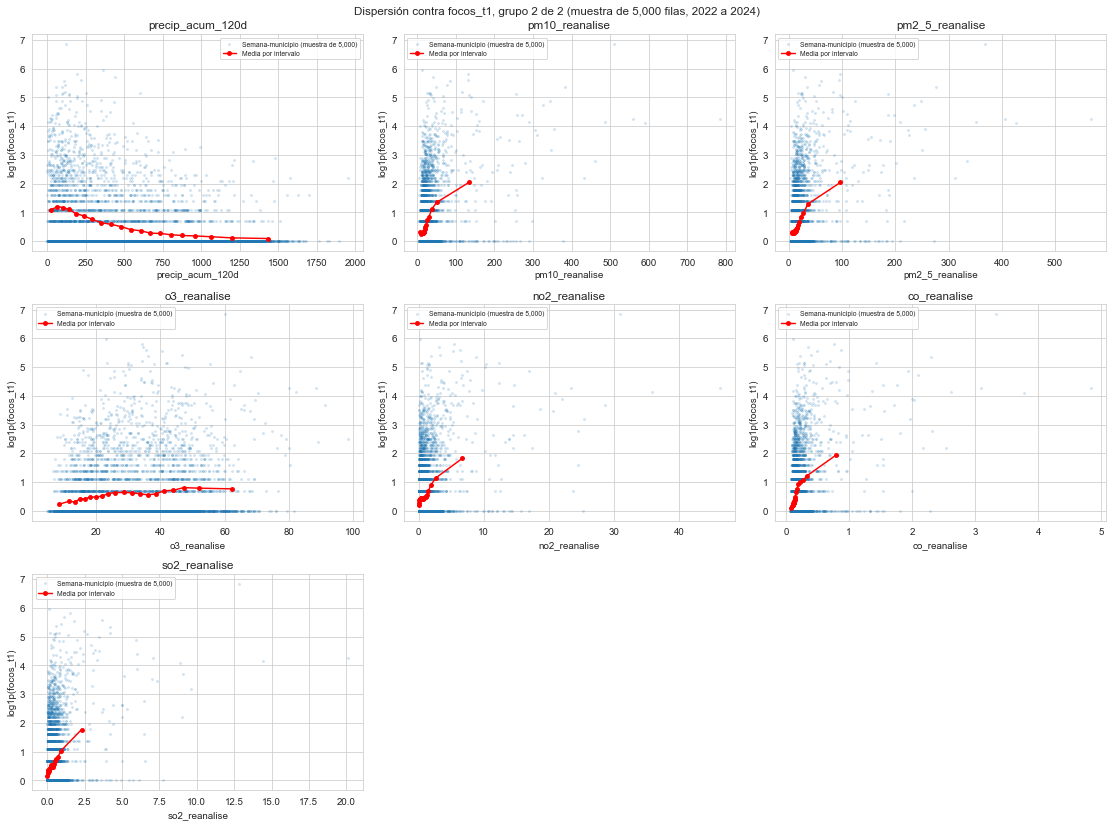

In [48]:
graficar_dispersion(GRUPO_2, "focos_t1", "Dispersión contra focos_t1, grupo 2 de 2 (muestra de 5,000 filas, 2022 a 2024)")
plt.show()


**Figura 24.** Dispersión de `precip_acum_120d` y las seis variables de SISAM contra `focos_t1` (en `log1p`), con la media por intervalos. Muestra de 5,000 filas de `ENT_OBJ`.


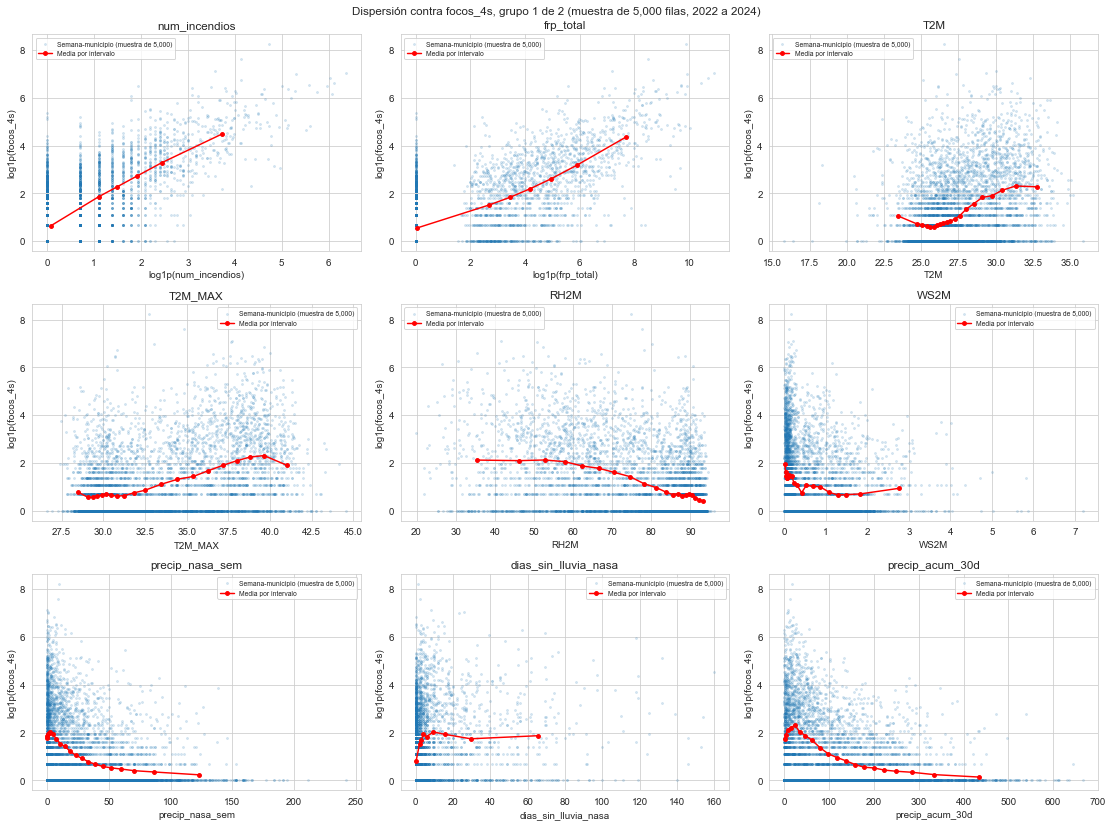

In [49]:
graficar_dispersion(GRUPO_1, "focos_4s", "Dispersión contra focos_4s, grupo 1 de 2 (muestra de 5,000 filas, 2022 a 2024)")
plt.show()


**Figura 25.** Dispersión de `num_incendios`, `frp_total` y siete variables de NASA POWER contra `focos_4s` (en `log1p`), con la media por intervalos. Muestra de 5,000 filas de `ENT_OBJ`.


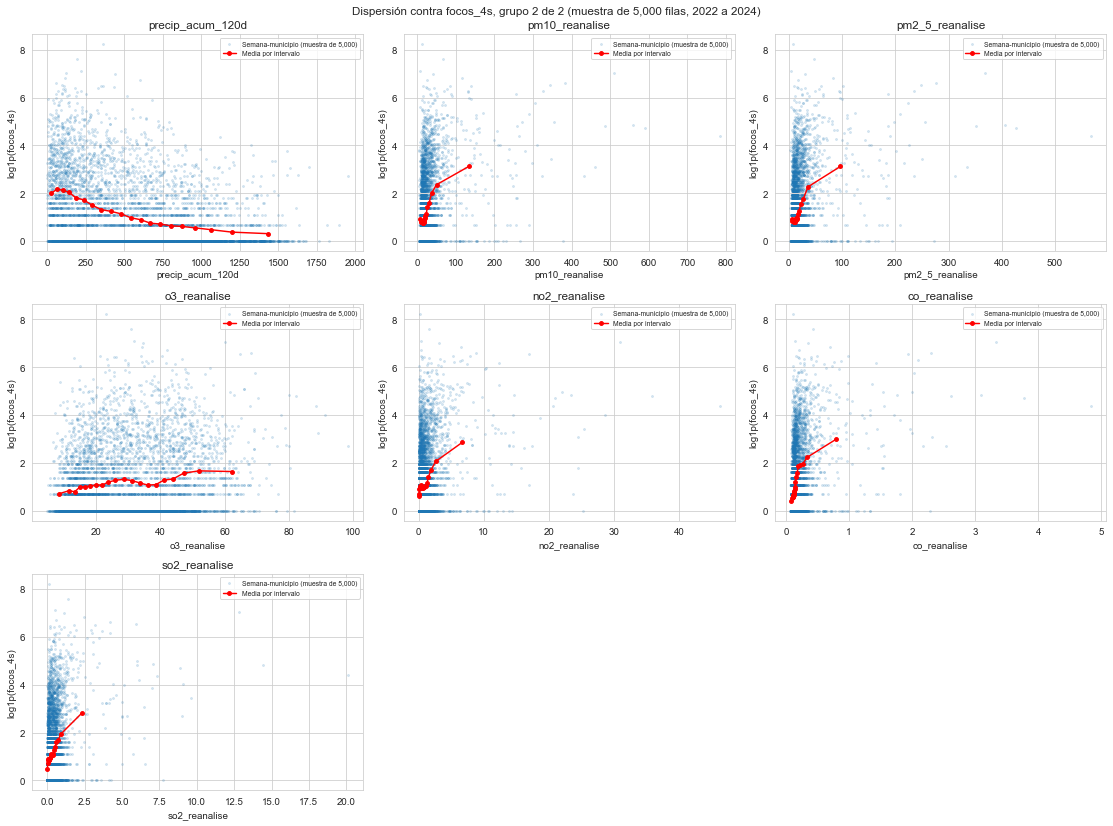

In [50]:
graficar_dispersion(GRUPO_2, "focos_4s", "Dispersión contra focos_4s, grupo 2 de 2 (muestra de 5,000 filas, 2022 a 2024)")
plt.show()


**Figura 26.** Dispersión de `precip_acum_120d` y las seis variables de SISAM contra `focos_4s` (en `log1p`), con la media por intervalos. Muestra de 5,000 filas de `ENT_OBJ`.


In [51]:
print(f"Correlación de cada par predictora-target ({len(base_corr):,} filas, 2022 a 2024):")
mostrar(resumen_corr.loc[PRED_DISP], 3)


Correlación de cada par predictora-target (83,079 filas, 2022 a 2024):
                     focos_t1          focos_4s         
                      pearson spearman  pearson spearman
predictora                                              
num_incendios           0.780    0.629    0.655    0.657
frp_total               0.732    0.627    0.624    0.655
T2M                     0.117    0.311    0.112    0.348
RH2M                   -0.150   -0.354   -0.156   -0.409
WS2M                   -0.071   -0.187   -0.081   -0.202
T2M_MAX                 0.136    0.339    0.135    0.378
precip_nasa_sem        -0.101   -0.329   -0.119   -0.424
dias_sin_lluvia_nasa    0.054    0.277    0.067    0.350
precip_acum_30d        -0.124   -0.383   -0.145   -0.487
precip_acum_120d       -0.130   -0.373   -0.134   -0.420
pm10_reanalise          0.314    0.308    0.262    0.283
pm2_5_reanalise         0.312    0.282    0.259    0.244
o3_reanalise            0.079    0.135    0.066    0.139
no2_reanalise    

In [52]:
VARS_BOX = ["T2M_MAX", "RH2M", "precip_acum_30d", "dias_sin_lluvia_nasa", "num_incendios", "riesgo_fuego_promedio", "pm10_reanalise"]
COLORES_CLASE = dict(zip(CLASES, sns.color_palette("RdYlGn_r", 4)))
datos_box = df.loc[ENT_OBJ & df["clase_t1"].notna(), VARS_BOX + ["clase_t1"]]
print(f"Filas con clase_t1 (2022 a 2024): {len(datos_box):,}")
print("\nMediana de cada predictora por clase de la semana siguiente:")
mostrar(datos_box.groupby("clase_t1", observed=True)[VARS_BOX].median(), 3)


Filas con clase_t1 (2022 a 2024): 26,351

Mediana de cada predictora por clase de la semana siguiente:
          T2M_MAX   RH2M  precip_acum_30d  dias_sin_lluvia_nasa  num_incendios  riesgo_fuego_promedio  pm10_reanalise
clase_t1                                                                                                             
Bajo       33.350 79.985           95.675                 0.000          1.000                  0.098          19.679
Moderado   36.570 65.422           30.445                 3.000          4.000                  0.522          25.707
Alto       37.050 61.217           17.240                 7.000          4.000                  0.805          23.496
Crítico    38.120 52.477            5.680                15.000          2.000                  1.000          25.271


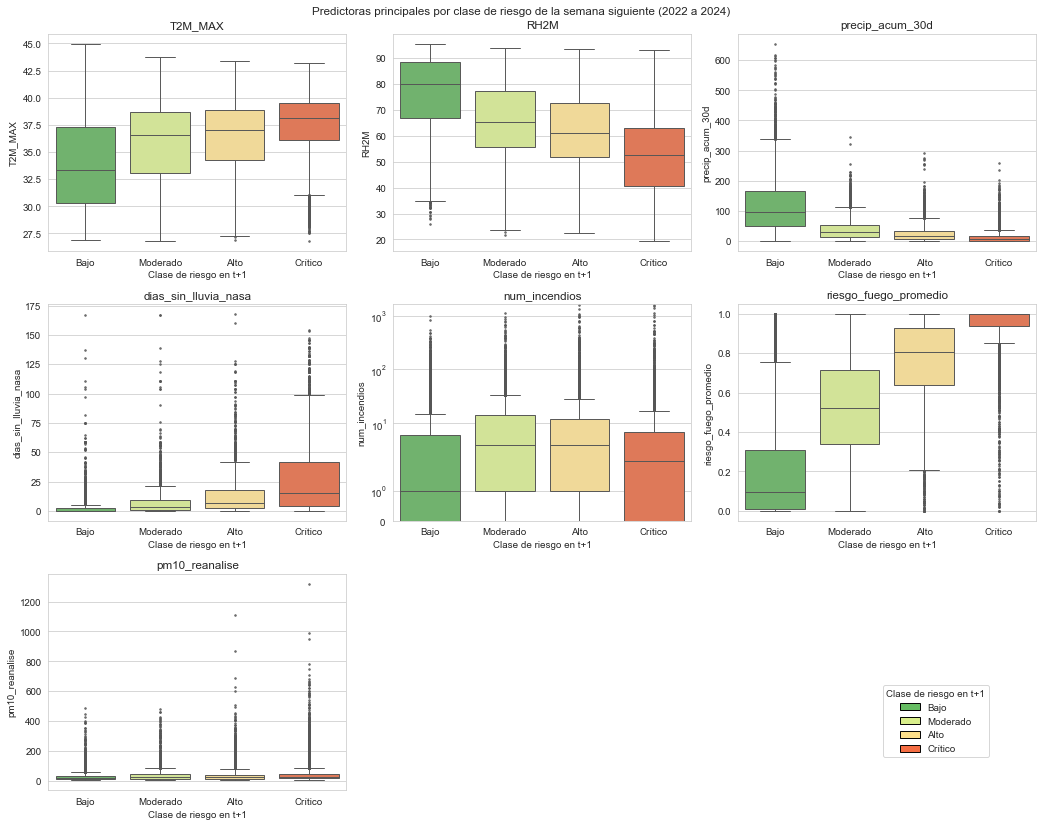

In [53]:
fig, ejes = plt.subplots(3, 3, figsize=(15, 12))
for eje, variable in zip(ejes.ravel(), VARS_BOX):
    sns.boxplot(data=datos_box, x="clase_t1", y=variable, order=CLASES, hue="clase_t1", hue_order=CLASES,
                palette=COLORES_CLASE, dodge=False, fliersize=1.5, ax=eje, legend=False)
    if variable == "num_incendios":
        eje.set_yscale("symlog")
        eje.set_ylim(bottom=0)
    eje.set_title(variable)
    eje.set_xlabel("Clase de riesgo en t+1")
    eje.set_ylabel(variable)
for eje in ejes.ravel()[len(VARS_BOX):]:
    eje.axis("off")
fig.legend(handles=[Patch(facecolor=COLORES_CLASE[c], edgecolor="k", label=c) for c in CLASES], title="Clase de riesgo en t+1",
           loc="lower right", bbox_to_anchor=(0.95, 0.08))
fig.suptitle("Predictoras principales por clase de riesgo de la semana siguiente (2022 a 2024)")
fig.tight_layout()
plt.show()


**Figura 27.** Boxplots de siete predictoras por `clase_t1` (Frente 2). Subconjunto `ENT_OBJ` con riesgo calculado en la semana siguiente, 2022 a 2024.


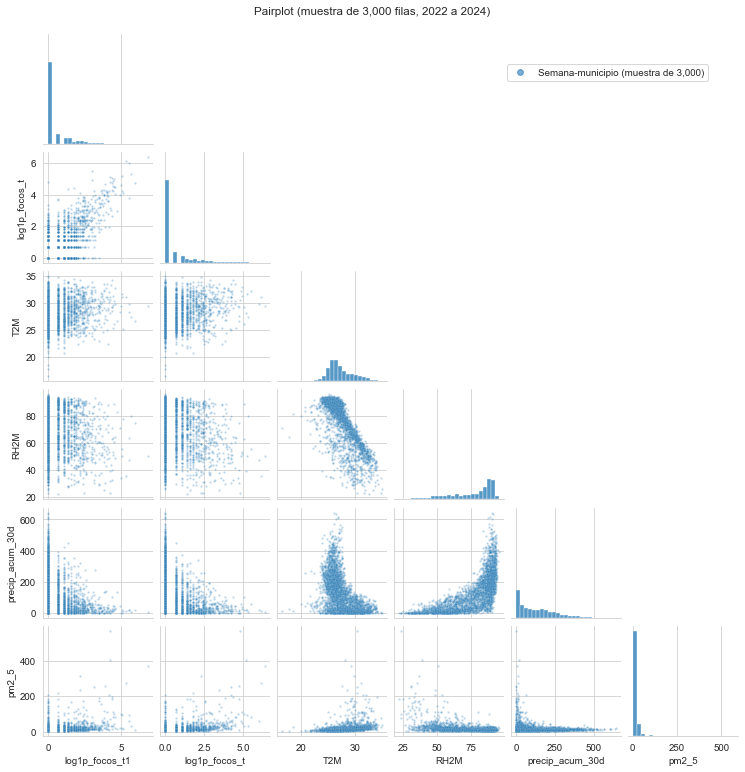

In [54]:
muestra_par = base_disp.sample(3000, random_state=ALEATORIO)
datos_par = pd.DataFrame({
    "log1p_focos_t1": np.log1p(muestra_par["focos_t1"]),
    "log1p_focos_t": np.log1p(muestra_par["num_incendios"]),
    "T2M": muestra_par["T2M"],
    "RH2M": muestra_par["RH2M"],
    "precip_acum_30d": muestra_par["precip_acum_30d"],
    "pm2_5": muestra_par["pm2_5_reanalise"],
})
grafico = sns.pairplot(datos_par, corner=True, plot_kws={"s": 5, "alpha": 0.3}, diag_kws={"bins": 25}, height=1.8)
grafico.figure.suptitle("Pairplot (muestra de 3,000 filas, 2022 a 2024)", y=1.02)
grafico.figure.legend(handles=[Line2D([0], [0], marker="o", linestyle="", color="tab:blue", alpha=0.6, label="Semana-municipio (muestra de 3,000)")],
                      loc="upper right", bbox_to_anchor=(0.95, 0.95))
plt.show()


**Figura 28.** Pairplot de seis variables (focos en `log1p`, clima y PM2.5). Muestra de 3,000 filas de `ENT_OBJ`.


### Hallazgos de esta etapa

**Qué se observa**
- En la tabla de correlaciones, `precip_acum_30d` tiene la mayor correlación de Spearman ambiental con `focos_4s` (**-0.487**), seguida de `co_reanalise` (**0.421**), `precip_acum_120d` (**-0.420**) y `RH2M` (**-0.409**). Con `focos_t1`, `precip_acum_30d` da **-0.383**. Su Pearson con `focos_t1` es de solo **-0.124**.
- En los gráficos de dispersión, la media de `log1p` del target baja cuando suben la lluvia acumulada y la humedad, y sube con la temperatura máxima y con `pm10_reanalise`, `pm2_5_reanalise`, `no2_reanalise`, `co_reanalise` y `so2_reanalise`. `o3_reanalise` casi no cambia.
- Para el Frente 2 hay **26,351** filas con `clase_t1`. Las medianas por clase (Bajo, Moderado, Alto, Crítico) son: `precip_acum_30d` **95.675**, **30.445**, **17.240** y **5.680**; `RH2M` de **79.985** a **52.477**; `T2M_MAX` de **33.350** a **38.120**; y `dias_sin_lluvia_nasa` de **0.000** a **15.000**.
- `pm10_reanalise` casi no separa las clases (**19.679**, **25.707**, **23.496** y **25.271**), y `num_incendios` no sube de forma ordenada (**1.000**, **4.000**, **4.000** y **2.000**).
- Gráficos de apoyo: Figura 23, Figura 24, Figura 25, Figura 26, Figura 27 y Figura 28.

**Por qué importa**
- Las variables de clima ordenan las clases de riesgo de forma ordenada, y la calidad del aire casi no lo hace. En esta muestra el riesgo se asocia más con el clima que con el número de focos.
- **`RiscoFogo` es un índice que INPE calcula a partir de lluvia, días sin lluvia y humedad.** El target del Frente 2 es en parte una función del clima, así que esta fuerte asociación es esperable y **no demuestra capacidad predictiva por sí sola**.
- Las relaciones con el target no son lineales y hay muchos ceros, por eso el Pearson subestima lo que muestra el Spearman.

**Qué implica para Data Preparation y el modelado**
- Para el Frente 2 se priorizan las variables de clima de NASA POWER (lluvia acumulada, días sin lluvia, humedad y temperatura máxima).
- Se permiten efectos no lineales en los modelos (por ejemplo árboles o transformaciones).
- **Limitación:** `riesgo_fuego_promedio` solo existe en semanas con focos, así que no está disponible para todas las filas.
- **Limitación:** como el target del Frente 2 se construye en parte con las mismas variables de clima, las métricas del Frente 2 deben interpretarse con cautela y no como prueba de que el modelo anticipa el fuego más allá de reproducir el índice. Hay que declararlo en el informe.


## 12. Contexto DETER y SISAM

**DETER** (alertas de deforestación) no es target ni predictora: es solo contexto de un KPI. Se mide su relación con los focos a nivel semanal (suma de todos los municipios) y a nivel municipio-semana, con 2022 a 2024.

**SISAM** cambia de fuente: reanálisis de 2022 a 2025 y pronóstico en 2026. Se compara el nivel de cada variable entre fuentes en el **mismo tramo del año** (semanas 1 a 42, que es hasta donde llega 2026), para no confundir el cambio de fuente con la estacionalidad. Esto decide qué se hace con SISAM en la ablación.


Correlación semanal (suma de municipios), 2022 a 2024:
                   pearson  spearman
deter_area_ha        0.552     0.778
deter_num_alertas    0.673     0.785

Correlación a nivel municipio-semana (Spearman) con num_incendios:
                                  spearman
deter_num_alertas                    0.407
deter_area_ha                        0.406
deter_num_alertas_area_protegida     0.158


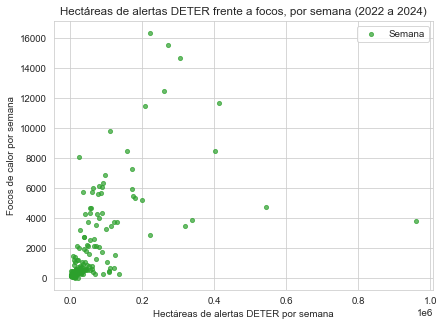

In [55]:
semanal_ctx = df[ENT].groupby("semana")[["num_incendios", "deter_area_ha", "deter_num_alertas"]].sum()
print("Correlación semanal (suma de municipios), 2022 a 2024:")
mostrar(pd.DataFrame({
    "pearson": [semanal_ctx["num_incendios"].corr(semanal_ctx[c]) for c in ["deter_area_ha", "deter_num_alertas"]],
    "spearman": [semanal_ctx["num_incendios"].corr(semanal_ctx[c], method="spearman") for c in ["deter_area_ha", "deter_num_alertas"]],
}, index=["deter_area_ha", "deter_num_alertas"]), 3)

print("\nCorrelación a nivel municipio-semana (Spearman) con num_incendios:")
mostrar(pd.DataFrame({"spearman": [df.loc[ENT, "num_incendios"].corr(df.loc[ENT, c], method="spearman") for c in COLS_DETER]}, index=COLS_DETER), 3)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(semanal_ctx["deter_area_ha"], semanal_ctx["num_incendios"], s=18, alpha=0.7, color="tab:green", label="Semana")
ax.set_title("Hectáreas de alertas DETER frente a focos, por semana (2022 a 2024)")
ax.set_xlabel("Hectáreas de alertas DETER por semana")
ax.set_ylabel("Focos de calor por semana")
ax.legend()
plt.show()


**Figura 29.** Cada punto es una semana: hectáreas de alertas DETER frente a focos totales (suma de municipios). Subconjunto `ENT`, 2022 a 2024.


Media de cada variable SISAM en las semanas 1 a 42 de cada periodo:
                 reanalisis_2022_2024  reanalisis_2025  pronostico_2026  razon_2026_sobre_2025
pm10_reanalise                  24.84            15.45             9.19                   0.60
pm2_5_reanalise                 18.16            11.27             7.80                   0.69
o3_reanalise                    29.27            30.75            41.59                   1.35
no2_reanalise                    1.07             0.63             2.17                   3.43
co_reanalise                     0.18             0.15             0.15                   1.00
so2_reanalise                    0.41             0.29             0.41                   1.43

Fuente SISAM por año (semanas-municipio):
fuente_sisam  mixta  pronostico  reanalise
anio                                      
2022              0           0      28236
2023              0           0      28236
2024              0           0      28779
2025     

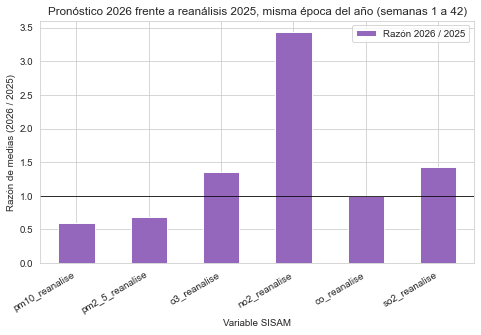

In [56]:
tramo = df["sem_anio"] <= 42
medias_sisam = pd.DataFrame({
    "reanalisis_2022_2024": df.loc[ENT & tramo, COLS_SISAM].mean(),
    "reanalisis_2025": df.loc[(df["anio"] == 2025) & tramo, COLS_SISAM].mean(),
    "pronostico_2026": df.loc[(df["anio"] == 2026) & tramo, COLS_SISAM].mean(),
})
medias_sisam["razon_2026_sobre_2025"] = medias_sisam["pronostico_2026"] / medias_sisam["reanalisis_2025"]
print("Media de cada variable SISAM en las semanas 1 a 42 de cada periodo:")
mostrar(medias_sisam, 2)
print("\nFuente SISAM por año (semanas-municipio):")
print(pd.crosstab(df["anio"], df["fuente_sisam"]).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
medias_sisam["razon_2026_sobre_2025"].plot(kind="bar", ax=ax, color="tab:purple", label="Razón 2026 / 2025")
ax.axhline(1, color="k", linewidth=0.8)
ax.set_title("Pronóstico 2026 frente a reanálisis 2025, misma época del año (semanas 1 a 42)")
ax.set_xlabel("Variable SISAM")
ax.set_ylabel("Razón de medias (2026 / 2025)")
plt.xticks(rotation=30, ha="right")
ax.legend()
plt.show()


**Figura 30.** Razón entre la media del pronóstico de 2026 y la del reanálisis de 2025 para cada variable de SISAM, en las semanas 1 a 42. Es descriptivo.


### Hallazgos de esta etapa

**Qué se observa**
- La correlación de Spearman semanal entre los focos y DETER es **0.778** (hectáreas) y **0.785** (alertas). A nivel municipio-semana baja a **0.406** y **0.407**.
- En las semanas 1 a 42, la media de `pm10_reanalise` es **24.84** (2022 a 2024), **15.45** (2025) y **9.19** (2026, pronóstico): la razón 2026 sobre 2025 es **0.60**. En `pm2_5_reanalise` es **0.69**, en `o3_reanalise` **1.35** y en `no2_reanalise` **3.43**. `co_reanalise` queda en **1.00**.
- En 2025 hay **543** semanas-municipio con fuente `mixta`; las **22,806** de 2026 son todas pronóstico.
- Gráficos de apoyo: Figura 29 y Figura 30.

**Por qué importa**
- DETER y los focos comparten la misma estacionalidad, por eso se correlacionan. Eso no lo convierte en predictora: es contexto para el KPI.
- El cambio de nivel de SISAM en 2026 mezcla dos efectos: cambio de producto (reanálisis a pronóstico) y menos focos. Ya entre 2022 a 2024 y 2025, con la misma fuente, `pm10_reanalise` bajó de **24.84** a **15.45**.

**Qué implica para Data Preparation y el modelado**
- La ablación de SISAM se evalúa en 2025 (reanálisis). En 2026 se compara con y sin SISAM.
- **Limitación:** el pronóstico de 2026 (con la interpretación `_forecast_0` como plazo 0) no está calibrado frente al reanálisis, y no se puede separar el efecto de la fuente del de los focos.


## 13. Desplazamiento entre periodos (drift)

Se compara cada variable entre **2022 a 2024 (referencia)**, **2025** y **2026**, con media, mediana y percentil 95, más el **índice de estabilidad de la población (PSI, 10 intervalos por deciles de 2022 a 2024)** y el estadístico de Kolmogorov-Smirnov (KS) frente a 2022 a 2024. Referencias habituales: PSI menor a 0.10 sin cambio relevante, de 0.10 a 0.25 cambio moderado, mayor a 0.25 cambio fuerte. Para que 2026 (que llega hasta la semana 42) sea comparable, **todos los periodos se restringen a las semanas 1 a 42 del año**. Aquí 2025 y 2026 solo se describen; no se usan para decidir transformaciones.


In [57]:
VARS_DRIFT = ["num_incendios", "frp_total", "frp_promedio", "riesgo_fuego_promedio", "precipitacion_promedio", "dias_sin_lluvia_promedio"] \
    + COLS_NASA + COLS_SISAM + COLS_DETER
tramo = df["sem_anio"] <= 42
PERIODOS = {"2022_2024": ENT & tramo, "2025": (df["anio"] == 2025) & tramo, "2026": (df["anio"] == 2026) & tramo}

filas = []
for variable in VARS_DRIFT:
    fila = {"variable": variable}
    for nombre, mascara in PERIODOS.items():
        x = df.loc[mascara, variable].dropna()
        fila[f"media_{nombre}"] = x.mean()
        fila[f"mediana_{nombre}"] = x.median()
        fila[f"p95_{nombre}"] = x.quantile(0.95)
    filas.append(fila)
tabla_descriptiva_drift = pd.DataFrame(filas).set_index("variable")
print("Media, mediana y percentil 95 por periodo (semanas 1 a 42 del año):")
print(tabla_descriptiva_drift.to_string(float_format=lambda v: f"{v:,.2f}"))


Media, mediana y percentil 95 por periodo (semanas 1 a 42 del año):


                                  media_2022_2024  mediana_2022_2024  p95_2022_2024  media_2025  mediana_2025  p95_2025  media_2026  mediana_2026  p95_2026
variable                                                                                                                                                   
num_incendios                                4.18               0.00          14.00        1.17          0.00      6.00        1.96          0.00      8.00
frp_total                                  272.96               0.00         614.61       57.64          0.00    161.95       82.36          0.00    228.07
frp_promedio                                34.65              23.50          96.44       28.49         18.56     82.04       26.76         17.81     75.15
riesgo_fuego_promedio                        0.49               0.48           1.00        0.51          0.52      1.00        0.61          0.69      1.00
precipitacion_promedio                       1.79              

In [58]:
def indice_psi(base, comparacion, cajas=10):
    # PSI con cortes por cuantiles de la base; devuelve NaN si la base casi no tiene valores distintos
    interiores = np.unique(np.quantile(base, np.linspace(0, 1, cajas + 1)[1:-1]))
    if len(interiores) < 2:
        return np.nan
    p = np.bincount(np.searchsorted(interiores, base), minlength=len(interiores) + 1) / len(base)
    q = np.bincount(np.searchsorted(interiores, comparacion), minlength=len(interiores) + 1) / len(comparacion)
    p, q = np.clip(p, 1e-4, None), np.clip(q, 1e-4, None)
    return float(np.sum((q - p) * np.log(q / p)))


filas = []
for variable in VARS_DRIFT:
    base = df.loc[PERIODOS["2022_2024"], variable].dropna().to_numpy()
    fila = {"variable": variable}
    for nombre in ["2025", "2026"]:
        comparacion = df.loc[PERIODOS[nombre], variable].dropna().to_numpy()
        fila[f"psi_{nombre}"] = indice_psi(base, comparacion)
        fila[f"ks_{nombre}"] = stats.ks_2samp(base, comparacion).statistic
    filas.append(fila)
tabla_drift = pd.DataFrame(filas).set_index("variable")
tabla_drift["ks_maximo"] = tabla_drift[["ks_2025", "ks_2026"]].max(axis=1)
tabla_drift = tabla_drift.sort_values("ks_maximo", ascending=False)
print("PSI y KS frente a 2022 a 2024, ordenado por el mayor KS (PSI vacío = variable casi constante):")
mostrar(tabla_drift, 3)


PSI y KS frente a 2022 a 2024, ordenado por el mayor KS (PSI vacío = variable casi constante):
                                  psi_2025  ks_2025  psi_2026  ks_2026  ks_maximo
variable                                                                         
pm10_reanalise                       0.279    0.207     2.473    0.640      0.640
pm2_5_reanalise                      0.262    0.205     1.682    0.538      0.538
no2_reanalise                        0.131    0.125     1.056    0.437      0.437
o3_reanalise                         0.072    0.083     0.750    0.342      0.342
riesgo_fuego_promedio                0.026    0.047     0.173    0.173      0.173
precip_acum_120d                     0.091    0.115     0.138    0.144      0.144
frp_promedio                         0.082    0.123     0.108    0.139      0.139
so2_reanalise                        0.060    0.070     0.184    0.133      0.133
T2M                                  0.094    0.108     0.142    0.127      0.127
T2M

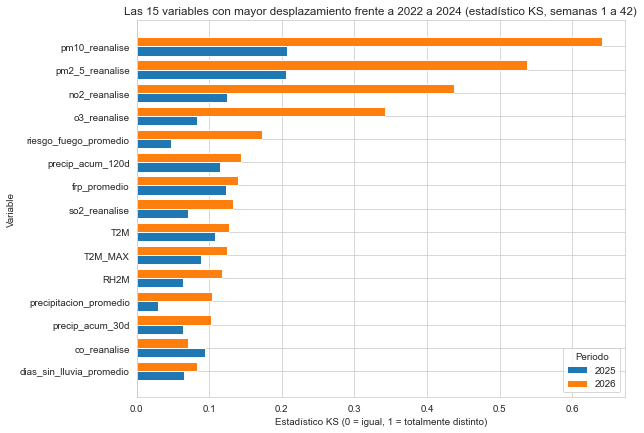

In [59]:
mayores = tabla_drift.head(15).sort_values("ks_maximo")
fig, ax = plt.subplots(figsize=(9, 7))
posicion = np.arange(len(mayores))
ax.barh(posicion - 0.2, mayores["ks_2025"], height=0.4, label="2025", color="tab:blue")
ax.barh(posicion + 0.2, mayores["ks_2026"], height=0.4, label="2026", color="tab:orange")
ax.set_yticks(posicion)
ax.set_yticklabels(mayores.index)
ax.set_title("Las 15 variables con mayor desplazamiento frente a 2022 a 2024 (estadístico KS, semanas 1 a 42)")
ax.set_xlabel("Estadístico KS (0 = igual, 1 = totalmente distinto)")
ax.set_ylabel("Variable")
ax.legend(title="Periodo")
plt.show()


**Figura 31.** Estadístico KS de 2025 y de 2026 frente a 2022 a 2024 para las 15 variables con mayor cambio, en las semanas 1 a 42. Es descriptivo.


In [60]:
presencia = df.groupby("anio")["num_incendios"].agg(
    pct_semanas_con_focos=lambda s: (s > 0).mean() * 100, focos_por_municipio_semana="mean")
presencia["pct_semanas_con_focos_sem_1_a_42"] = df[tramo].groupby("anio")["num_incendios"].apply(lambda s: (s > 0).mean() * 100)
print("Presencia de focos por año:")
mostrar(presencia, 2)

riesgo_anio = pd.crosstab(df.loc[tramo, "anio"], df.loc[tramo, "clase_t"], normalize="index") * 100
print("\nClase de riesgo por año, semanas 1 a 42 (% de las semanas con riesgo calculado):")
mostrar(riesgo_anio, 1)


Presencia de focos por año:
      pct_semanas_con_focos  focos_por_municipio_semana  pct_semanas_con_focos_sem_1_a_42
anio                                                                                     
2022                  29.46                        4.07                             26.36
2023                  32.88                        3.49                             28.48
2024                  33.32                        4.89                             30.11
2025                  24.70                        1.54                             20.71
2026                  21.92                        1.96                             21.92

Clase de riesgo por año, semanas 1 a 42 (% de las semanas con riesgo calculado):
clase_t  Bajo  Moderado  Alto  Crítico
anio                                  
2022     45.9      16.8  16.0     21.2
2023     51.9      17.4  15.9     14.9
2024     40.9      14.2  17.4     27.6
2025     42.2      19.0  18.8     20.0
2026     29.0      22.4  2

### Hallazgos de esta etapa

**Qué se observa**
- Los focos bajan: el porcentaje de semanas con focos es **29.46 %**, **32.88 %** y **33.32 %** (2022 a 2024), y **24.70 %** (2025) y **21.92 %** (2026). En las semanas 1 a 42, `num_incendios` promedia **4.18**, **1.17** y **1.96** (2022 a 2024, 2025 y 2026).
- Las variables con mayor desplazamiento son las de SISAM en 2026: `pm10_reanalise` (KS **0.640**, PSI **2.473**), `pm2_5_reanalise` (**0.538**, **1.682**), `no2_reanalise` (**0.437**, **1.056**) y `o3_reanalise` (**0.342**, **0.750**).
- El clima de NASA POWER cambia poco: el mayor KS es **0.144** (`precip_acum_120d` en 2026).
- En las semanas 1 a 42, la clase Crítico fue **27.6 %** en 2024, frente a **21.2 %** (2022) y **14.9 %** (2023). En 2025 fue **20.0 %** y en 2026 **24.8 %**.
- Gráficos de apoyo: Figura 31.

**Por qué importa**
- El clima es estable entre periodos, pero el nivel de focos y la calidad del aire no. Los modelos entrenados en 2022 a 2024 verán en 2025 y 2026 una distribución distinta.
- El año 2024 es atípico en la proporción de Crítico.

**Qué implica para Data Preparation y el modelado**
- **Limitación:** hay desplazamiento en los focos (menor nivel), en `RiscoFogo` y en SISAM (cambio de fuente). Las métricas de 2025 y 2026 se reportan por separado y con cautela.
- Se monitorea el PSI de las variables de SISAM antes de usarlas en el flujo simulado de 2026.


## 14. Evidencia para umbrales de KPI

Evidencia descriptiva con **2022 a 2024**; los umbrales definitivos se fijan en Data Preparation. Se calculan los percentiles 50 y 75 de los focos por municipio-semana **entre las semanas con focos**, por temporada, que sirven para definir los niveles Habitual (hasta el percentil 50), Elevado (entre el 50 y el 75) y Muy elevado (más del percentil 75). Luego se cuenta cuántos municipios quedan "en alerta" por semana y se compara con la **capacidad de referencia de 70 municipios**, con sensibilidad de 60 a 150. Para este conteo provisional, "en alerta" significa nivel Elevado o Muy elevado de su temporada.


In [61]:
positivos = df[ENT & (df["num_incendios"] > 0)]
percentiles_pos = positivos.groupby("temporada")["num_incendios"].quantile([0.5, 0.75, 0.9, 0.95]).unstack()
percentiles_pos.columns = ["p50", "p75", "p90", "p95"]
print("Percentiles de focos por municipio-semana entre las semanas con focos (2022 a 2024):")
mostrar(percentiles_pos, 1)

todas = df[ENT].groupby("temporada")["num_incendios"].quantile([0.5, 0.75, 0.9, 0.95]).unstack()
todas.columns = ["p50", "p75", "p90", "p95"]
print("\nReferencia, percentiles sobre todas las semanas (incluye ceros):")
mostrar(todas, 1)

df["nivel_kpi"] = "Sin focos"
for temporada in ["seca", "humeda"]:
    p50, p75 = percentiles_pos.loc[temporada, ["p50", "p75"]]
    en_temporada = (df["temporada"] == temporada) & (df["num_incendios"] > 0)
    df.loc[en_temporada, "nivel_kpi"] = np.select(
        [df.loc[en_temporada, "num_incendios"] <= p50, df.loc[en_temporada, "num_incendios"] <= p75],
        ["Habitual", "Elevado"], default="Muy elevado")
niveles = pd.crosstab(df.loc[ENT, "temporada"], df.loc[ENT, "nivel_kpi"], normalize="index") * 100
print("\nDistribución provisional de niveles por temporada (% de semanas-municipio, 2022 a 2024):")
mostrar(niveles[["Sin focos", "Habitual", "Elevado", "Muy elevado"]], 1)


Percentiles de focos por municipio-semana entre las semanas con focos (2022 a 2024):
           p50  p75  p90  p95
temporada                    
humeda     2.0  5.0 11.0 17.0
seca       4.0 12.0 34.0 67.0

Referencia, percentiles sobre todas las semanas (incluye ceros):
           p50  p75  p90  p95
temporada                    
humeda     0.0  0.0  2.0  4.0
seca       1.0  4.0 16.0 35.0

Distribución provisional de niveles por temporada (% de semanas-municipio, 2022 a 2024):
nivel_kpi  Sin focos  Habitual  Elevado  Muy elevado
temporada                                           
humeda          82.3      10.1      3.8          3.8
seca            48.5      26.9     12.4         12.2


Municipios en alerta por semana (2022 a 2024):
temporada  humeda  seca
count        91.0  66.0
mean         41.2 133.5
std          29.9  50.1
min           0.0  29.0
25%          22.0 101.2
50%          32.0 134.0
75%          51.5 173.5
90%          81.0 197.0
max         150.0 209.0

Sensibilidad a la capacidad de atención (semanas en que las alertas superan la capacidad):
                      pct_semanas_sobre_capacidad  pct_semanas_secas_sobre_capacidad
capacidad_municipios                                                                
60                                           48.4                               89.4
70                                           45.2                               86.4
80                                           42.0                               84.8
100                                          35.7                               74.2
120                                          26.1                               59.1
150                       

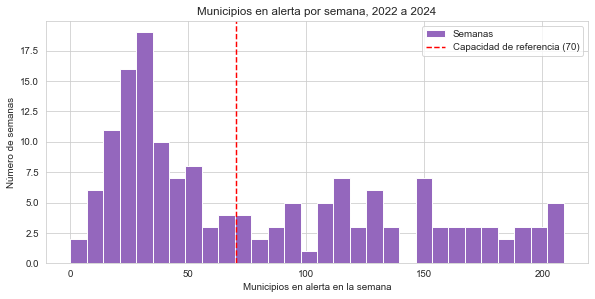

In [62]:
df["en_alerta"] = df["nivel_kpi"].isin(["Elevado", "Muy elevado"])
alertas_semana = df[ENT].groupby("semana")["en_alerta"].sum()
temporada_semana = df[ENT].groupby("semana")["temporada"].agg(lambda s: s.mode().iloc[0])

print("Municipios en alerta por semana (2022 a 2024):")
mostrar(alertas_semana.groupby(temporada_semana).describe(percentiles=[0.25, 0.5, 0.75, 0.9]).T, 1)

capacidades = [60, 70, 80, 100, 120, 150]
sensibilidad = pd.DataFrame({
    "pct_semanas_sobre_capacidad": [(alertas_semana > c).mean() * 100 for c in capacidades],
    "pct_semanas_secas_sobre_capacidad": [(alertas_semana[temporada_semana == "seca"] > c).mean() * 100 for c in capacidades],
}, index=pd.Index(capacidades, name="capacidad_municipios"))
print("\nSensibilidad a la capacidad de atención (semanas en que las alertas superan la capacidad):")
mostrar(sensibilidad, 1)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(alertas_semana, bins=30, color="tab:purple", label="Semanas")
ax.axvline(70, color="red", linestyle="--", label="Capacidad de referencia (70)")
ax.set_title("Municipios en alerta por semana, 2022 a 2024")
ax.set_xlabel("Municipios en alerta en la semana")
ax.set_ylabel("Número de semanas")
ax.legend()
plt.show()


**Figura 32.** Histograma del número de municipios en alerta (nivel Elevado o Muy elevado) por semana, con la capacidad de referencia de 70. Subconjunto `ENT`, 2022 a 2024.


### Hallazgos de esta etapa

**Qué se observa**
- Entre las semanas con focos, el percentil 50 y el 75 de focos por municipio-semana son **2.0** y **5.0** en la temporada húmeda, y **4.0** y **12.0** en la seca.
- Los niveles provisionales en la temporada seca son: sin focos **48.5 %**, Habitual **26.9 %**, Elevado **12.4 %** y Muy elevado **12.2 %**. En la húmeda: **82.3 %**, **10.1 %**, **3.8 %** y **3.8 %**.
- Los municipios en alerta por semana tienen mediana **134.0** en la seca (de **29** a **209**) y **32.0** en la húmeda (de **0** a **150**).
- Con una capacidad de 70 municipios, las alertas la superan en **45.2 %** de las semanas (**86.4 %** de las secas). Con capacidad 100 son **35.7 %**, y con 150 son **17.2 %** (**40.9 %** de las secas).
- Gráficos de apoyo: Figura 32.

**Por qué importa**
- Los umbrales deben variar por temporada: el percentil 75 de la seca (**12.0**) es más del doble que el de la húmeda (**5.0**).
- Definir "en alerta" como Elevado o Muy elevado supera una capacidad de 70 en **86.4 %** de las semanas secas.

**Qué implica para Data Preparation y el modelado**
- Los umbrales finales se fijan en Data Preparation. Hay que decidir si la alerta es solo Muy elevado o si cambia la capacidad de referencia.
- **Limitación:** los umbrales salen de 2022 a 2024, años con más focos por municipio-semana (**4.07**, **3.49** y **4.89**) que 2025 y 2026 (**1.54** y **1.96**).


## 15. Conclusiones y decisiones para Data Preparation

Cada decisión se apoya en una cifra de las secciones anteriores. Los umbrales y las definiciones formales se fijan en Data Preparation.

| Hallazgo | Evidencia (cifra) | Decisión |
|---|---|---|
| Targets con muchos ceros y cola extrema | `focos_t1` cero en **67.93 %**; asimetría de **24.673** a **2.140** con `log1p` | Modelar con `log1p`; aplicar `log1p` también a `frp_total`, contaminantes SISAM, `dias_sin_lluvia_nasa`, `WS2M` y `precip_nasa_sem`; no a `T2M`, `RH2M` ni acumulados |
| Los extremos de focos son reales | IQR marca **18.37 %** de `num_incendios`; máximo **1,569** en `SAO FELIX DO XINGU` (PA) | No eliminar ni recortar focos ni `frp_total` |
| Criterio de atípicos (normalidad evaluada antes) | **4** de 18 variables con asimetría entre -0.6 y 0.6 y curtosis entre -1.5 y 1.5 (`T2M` **0.560**, `T2M_MAX` **0.529**, `precip_acum_120d` **0.541**, `o3_reanalise` **0.591**) | 3 desviaciones estándar para esas 4 variables e IQR para las otras **14**; límites calculados solo con 2022 a 2024 |
| Nulos estructurales | **97,131** semanas-municipio sin focos (**71.3 %**) | No imputar; las columnas de clima de BDQueimadas no son predictoras |
| Nulos de `RiscoFogo` | **1.00 % a 1.13 %** (2022 a 2024) y **4.66 %** y **4.54 %** (2025 y 2026) en semanas con focos | Excluir esas semanas del target de clasificación; sin imputación |
| Colinealidad | **5** pares con |r| mayor a 0.9 (`pm10` con `pm2_5` **0.999**) | Retirar `pm2_5_reanalise`; un representante entre `pm10` y `co`, y otro entre `no2` y `so2`; `frp_total` candidata a retirarse; confirmar con VIF |
| Escala de las variables | Varianza de `frp_total` **5,972,475.08** frente a **0.04** de `co_reanalise`; la covarianza estandarizada coincide con la correlación | Estandarizar las predictoras para modelos sensibles a la escala; no seleccionar variables con la covarianza sin estandarizar |
| Rezagos | Correlación con el rezago 1 **0.780** y con el 4 **0.382**; NASA `precip_acum_30d` entre **-0.380** y **-0.396** | Construir rezagos de 1 a 4 semanas de `num_incendios` y de las variables de NASA |
| Aporte más allá de la persistencia | Spearman parcial de SISAM entre **0.051** y **0.171** y Pearson parcial con `log1p` entre **0.028** y **0.084**; NASA hasta **0.201** en valor absoluto. El Pearson parcial en escala original está dominado por extremos (`frp_total` **0.670**, `precip_acum_30d` **+0.040** frente a **-0.139** con `log1p`) | Leer el Spearman parcial y el Pearson con `log1p`; SISAM entra solo a la ablación (con y sin SISAM) |
| Clima para el Frente 2 | Mediana de `precip_acum_30d` de **95.675** (Bajo) a **5.680** (Crítico); `dias_sin_lluvia_nasa` de **0.000** a **15.000**; `pm10_reanalise` casi sin cambio | Priorizar el clima de NASA POWER en el clasificador; `num_incendios` no ordena las clases |
| Balance de clases | Bajo **48.6 %**, Moderado **15.7 %**, Alto **16.0 %**, Crítico **19.7 %** | SMOTE solo dentro del entrenamiento de cada partición; comparar con ponderación de clases |
| Estacionalidad y clase por mes | Temporada seca: **88.34 %** de los focos; Crítico llega a **33.5 %** en agosto y el **88.2 %** de las semanas Crítico cae en la seca | Variables de calendario (mes o semana del año y temporada) |
| Heterogeneidad por estado | `PA`, `AM` y `MT` aportan **37.74 %**, **17.54 %** y **17.02 %** del error de la persistencia; correlación `focos_t` con `focos_t1` de **0.24** en `RR` y `TO` frente a **0.78** a **0.79** en los cinco principales | Incluir `uf` y reportar métricas por estado |
| Partición | `ENT_OBJ`: **83,079** filas, hasta 2024-12-02 | Entrenar con 2022 a 2024 con validación cruzada temporal, margen de 4 semanas, prueba con 2025; 2026 solo flujo simulado |
| Piso del modelo | Persistencia: **MAE 3.343**, **RMSE 18.448**, accuracy de clase **66.1 %** | Todo modelo se compara contra este piso, global y solo en semanas con focos (**MAE 9.516**) |
| Desplazamiento | `pm10_reanalise` KS **0.640** en 2026; `num_incendios` **4.18** a **1.17** (2025); Crítico **27.6 %** en 2024; `RR` sube a **56.83 %** de semanas con focos en 2026 mientras `PA` baja a **27.98 %** | Reportar 2025 y 2026 por separado; declarar el desplazamiento como limitación |
| Umbrales de KPI | p50 y p75 de la seca: **4.0** y **12.0**; capacidad 70 superada en **45.2 %** de las semanas | Fijar umbrales por temporada y revisar la definición de alerta o la capacidad |
| DETER | Spearman semanal con focos **0.778** | Solo contexto de KPI: no es target ni predictora |


### Resumen para el informe

- **Dataset:** panel semanal de **543 municipios x 251 semanas = 136,293 filas** y 31 columnas, con ceros reales. Los focos son cero en **71.3 %** de las semanas-municipio.
- **Targets y atípicos:** `focos_t1` es cero en **67.93 %** de las filas de entrenamiento, con cola extrema (máximo **1,569**). Se modelan con `log1p` y los picos reales no se recortan. La normalidad se evaluó antes de tratar los atípicos: **3 desviaciones estándar** para 4 variables (`T2M`, `T2M_MAX`, `precip_acum_120d` y `o3_reanalise`) e **IQR** para las otras **14**.
- **Piso del modelo:** la persistencia da **MAE 3.343**, **RMSE 18.448** y **66.1 %** de accuracy de clase. La autocorrelación semanal es **0.888** en el rezago 1.
- **Estacionalidad y clase de riesgo:** la temporada seca reúne **88.34 %** de los focos. La clase Crítico llega a **33.5 %** en agosto y el **88.2 %** de las semanas Crítico cae en la seca.
- **Heterogeneidad por estado:** `PA`, `AM` y `MT` aportan **37.74 %**, **17.54 %** y **17.02 %** del error de la persistencia. **Limitación:** la persistencia casi no sirve en `RR` y `TO` (correlación **0.24**) y el desplazamiento difiere por estado.
- **Predictoras:** el Pearson parcial en escala original está dominado por extremos, y la lectura principal es el Spearman parcial y el Pearson con `log1p`. SISAM aporta poco (Spearman parcial de **0.051** a **0.171**; Pearson con `log1p` de **0.028** a **0.084**) y entra solo a la ablación. El clima de NASA POWER tiene señal pequeña pero real (hasta **0.201** en valor absoluto).
- **Colinealidad:** **5** pares con |r| mayor a 0.9. Se retira `pm2_5_reanalise` y se deja un representante por grupo.
- **Nulos:** los nulos de focos son estructurales y no se imputan. **Limitación:** `RiscoFogo` falta en cerca de **4.6 %** de las semanas con focos en 2025 y 2026, frente a cerca de **1.1 %** en 2022 a 2024; esas semanas se excluyen del target de clasificación.
- **Desplazamiento:** **Limitación:** los focos bajan (semanas con focos de **33.32 %** en 2024 a **24.70 %** en 2025) y SISAM cambia de fuente en 2026 (`pm10_reanalise` con KS **0.640**). Las métricas de 2025 y 2026 se reportan por separado.
- **Cobertura y partición:** **Limitación:** el panel solo incluye municipios con focos del bioma Amazônia y se excluyeron 9 municipios sin centroide, con **242** alertas DETER (cifras del notebook 03). Entrenamiento 2022 a 2024 (`ENT_OBJ`, **83,079** filas) con validación cruzada temporal y margen de 4 semanas, prueba con 2025, 2026 solo como flujo simulado, y SMOTE solo dentro del entrenamiento.
